# 01 — Exploratory Data Analysis & Data Quality
**Mercari Price Suggestion Challenge**  
**Member 1: Data Engineer** — Data Understanding, EDA & Preprocessing

Dataset: [Kaggle – Mercari Price Suggestion Challenge](https://www.kaggle.com/c/mercari-price-suggestion-challenge/data)  
Place `train.tsv` at `../data/train.tsv` (or update `DATA_PATH` in Step 2).

**Requirements:** `pandas numpy matplotlib seaborn scipy missingno`

In [4]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
pip install missingno

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from scipy import stats
from scipy.stats import skew, kurtosis
import re
from collections import Counter
import missingno as msno

# Configure visualizations
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
warnings.filterwarnings('ignore')
%matplotlib inline

# Set random seed for reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print("✅ Libraries imported successfully!")
print(f"📊 Pandas version: {pd.__version__}")
print(f"🔢 NumPy version: {np.__version__}")

✅ Libraries imported successfully!
📊 Pandas version: 3.0.3
🔢 NumPy version: 2.4.6


## Step 1: Import Libraries

## Step 2: Data Acquisition & Initial Inspection

In [6]:
# Load the dataset
# Dataset: Mercari Price Suggestion Challenge from Kaggle
# URL: https://www.kaggle.com/c/mercari-price-suggestion-challenge/data

DATA_PATH = "../data/train.tsv"  # Update path as needed

# Load data
df = pd.read_csv(DATA_PATH, sep='\t', encoding='utf-8')

print("=" * 60)
print("DATASET LOADED SUCCESSFULLY")
print("=" * 60)
print(f"📁 File Path: {DATA_PATH}")
print(f"📊 Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"💾 Memory Usage: {df.memory_usage(deep=True).sum() / 1024**2:.2f} MB")

DATASET LOADED SUCCESSFULLY
📁 File Path: ../data/train.tsv
📊 Shape: 1,482,535 rows × 8 columns
💾 Memory Usage: 384.38 MB


## Step 3: Data Structure & Schema Analysis

In [8]:
print("\n" + "=" * 60)
print("DATA STRUCTURE & SCHEMA")
print("=" * 60)

# Display basic info
print("\n📋 Column Names and Data Types:")
display(df.dtypes)

print("\n📋 First 5 Rows:")
display(df.head())

print("\n📋 Last 5 Rows:")
display(df.tail())

print("\n📋 Dataset Info:")
df.info()


DATA STRUCTURE & SCHEMA

📋 Column Names and Data Types:


train_id               int64
name                     str
item_condition_id      int64
category_name            str
brand_name               str
price                float64
shipping               int64
item_description         str
dtype: object


📋 First 5 Rows:


,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
0,0,MLB Cincinnati Reds T Shirt Size XL,3,Men/Tops/T-shirts,NaN,10.0,1,No description yet
1,1,Razer BlackWidow Chroma Keyboard,3,Electronics/Computers & Tablets/Components & P...,Razer,52.0,0,This keyboard is in great condition and works ...
2,2,AVA-VIV Blouse,1,Women/Tops & Blouses/Blouse,Target,10.0,1,Adorable top with a hint of lace and a key hol...
3,3,Leather Horse Statues,1,Home/Home Décor/Home Décor Accents,NaN,35.0,1,New with tags. Leather horses. Retail for [rm]...
4,4,24K GOLD plated rose,1,Women/Jewelry/Necklaces,NaN,44.0,0,Complete with certificate of authenticity



📋 Last 5 Rows:


,train_id,name,item_condition_id,category_name,brand_name,price,shipping,item_description
1482530,1482530,Free People Inspired Dress,2,Women/Dresses/Mid-Calf,Free People,20.0,1,"Lace, says size small but fits medium perfectl..."
1482531,1482531,Little mermaid handmade dress,2,Kids/Girls 2T-5T/Dresses,Disney,14.0,0,Little mermaid handmade dress never worn size 2t
1482532,1482532,21 day fix containers and eating plan,2,Sports & Outdoors/Exercise/Fitness accessories,NaN,12.0,0,"Used once or twice, still in great shape."
1482533,1482533,World markets lanterns,3,Home/Home Décor/Home Décor Accents,NaN,45.0,1,There is 2 of each one that you see! So 2 red ...
1482534,1482534,Brand new lux de ville wallet,1,Women/Women's Accessories/Wallets,NaN,22.0,0,"New with tag, red with sparkle. Firm price, no..."



📋 Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 1482535 entries, 0 to 1482534
Data columns (total 8 columns):
 #   Column             Non-Null Count    Dtype  
---  ------             --------------    -----  
 0   train_id           1482535 non-null  int64  
 1   name               1482535 non-null  str    
 2   item_condition_id  1482535 non-null  int64  
 3   category_name      1476208 non-null  str    
 4   brand_name         849853 non-null   str    
 5   price              1482535 non-null  float64
 6   shipping           1482535 non-null  int64  
 7   item_description   1482529 non-null  str    
dtypes: float64(1), int64(3), str(4)
memory usage: 384.4 MB


## Step 4: Statistical Summary

In [10]:
print("\n" + "=" * 60)
print("STATISTICAL SUMMARY")
print("=" * 60)

print("\n📊 Numerical Features Summary:")
display(df.describe().T)

print("\n📊 Categorical Features Summary:")
display(df.describe(include=['object']).T)


STATISTICAL SUMMARY

📊 Numerical Features Summary:


,count,mean,std,min,25%,50%,75%,max
train_id,1482535.0,741267.000000,427971.135004,0.0,370633.5,741267.0,1111900.5,1482534.0
item_condition_id,1482535.0,1.907380,0.903159,1.0,1.0,2.0,3.0,5.0
price,1482535.0,26.737516,38.586066,0.0,10.0,17.0,29.0,2009.0
shipping,1482535.0,0.447274,0.497212,0.0,0.0,0.0,1.0,1.0



📊 Categorical Features Summary:


,count,unique,top,freq
name,1482535,1225273,Bundle,2232
category_name,1476208,1287,"Women/Athletic Apparel/Pants, Tights, Leggings",60177
brand_name,849853,4809,PINK,54088
item_description,1482529,1281423,No description yet,82489


## Step 5: Data Quality Assessment


DATA QUALITY ASSESSMENT

🔍 MISSING VALUES ANALYSIS:
                  Missing Count  Missing Percentage Data Type
brand_name               632682           42.675687       str
category_name              6327            0.426769       str
item_description              6            0.000405       str


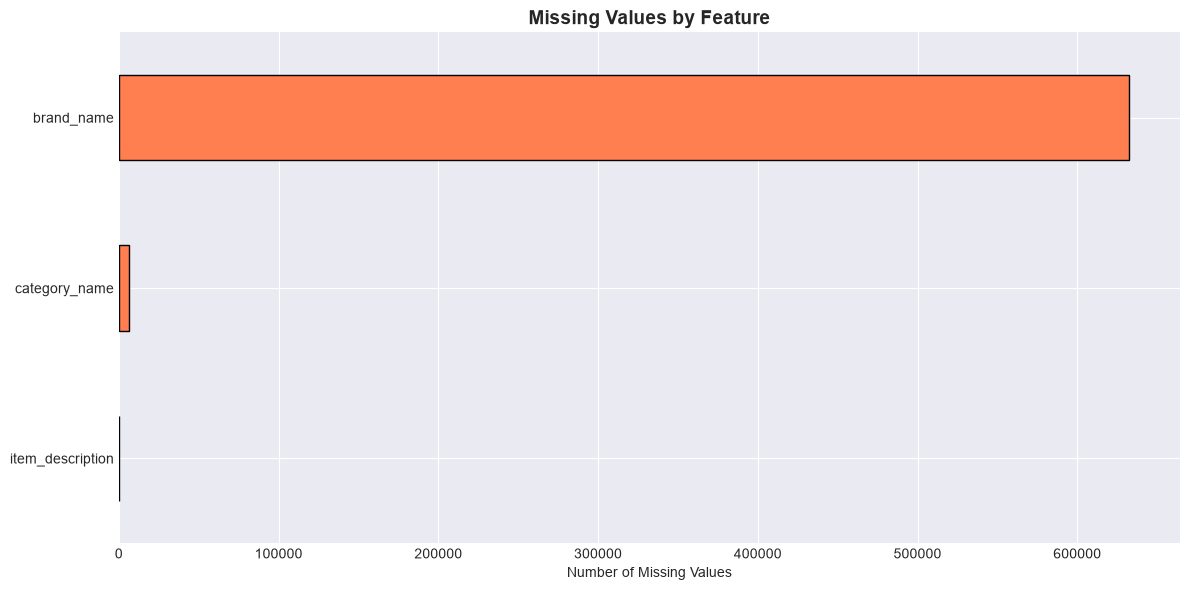

<Figure size 1200x600 with 0 Axes>

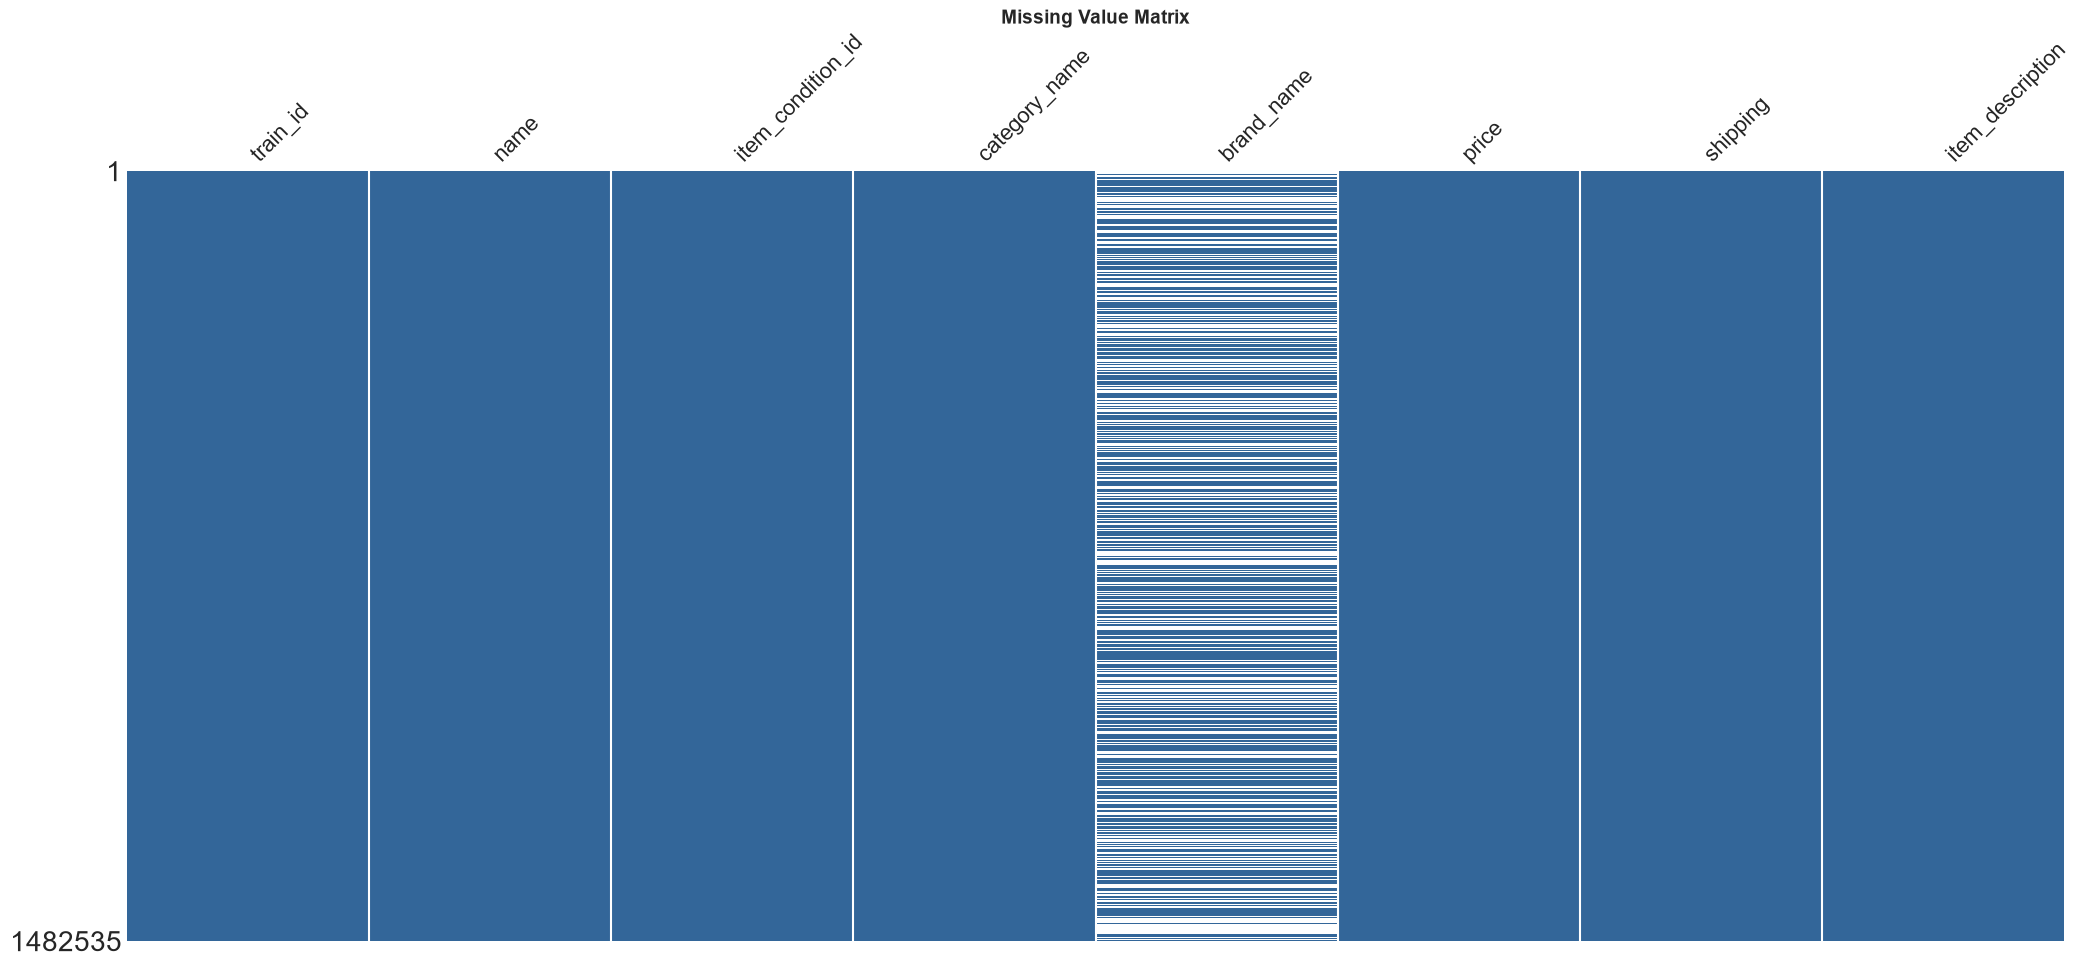


🔍 DUPLICATE RECORDS ANALYSIS:
Total duplicate rows: 0
Percentage of duplicates: 0.0000%
Duplicates based on key columns ['name', 'item_description', 'price']: 2466

🔍 DATA TYPE VALIDATION:
train_id: int64 | Unique values: 1482535
name: str | Unique values: 1225273
item_condition_id: int64 | Unique values: 5
category_name: str | Unique values: 1287
brand_name: str | Unique values: 4809
price: float64 | Unique values: 828
shipping: int64 | Unique values: 2
item_description: str | Unique values: 1281423


In [11]:
print("\n" + "=" * 60)
print("DATA QUALITY ASSESSMENT")
print("=" * 60)

# 5.1: Missing Values Analysis
print("\n🔍 MISSING VALUES ANALYSIS:")
missing_data = pd.DataFrame({
    'Missing Count': df.isnull().sum(),
    'Missing Percentage': (df.isnull().sum() / len(df)) * 100,
    'Data Type': df.dtypes
})
missing_data = missing_data[missing_data['Missing Count'] > 0].sort_values('Missing Count', ascending=False)
print(missing_data)

# Visualize missing values
plt.figure(figsize=(12, 6))
missing_counts = df.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=True)
missing_counts.plot(kind='barh', color='coral', edgecolor='black')
plt.xlabel('Number of Missing Values')
plt.title('Missing Values by Feature', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Missing value matrix
plt.figure(figsize=(12, 6))
msno.matrix(df, sparkline=False, color=(0.2, 0.4, 0.6))
plt.title('Missing Value Matrix', fontsize=14, fontweight='bold')
plt.show()

# 5.2: Duplicate Records Analysis
print("\n🔍 DUPLICATE RECORDS ANALYSIS:")
duplicates = df.duplicated().sum()
print(f"Total duplicate rows: {duplicates}")
print(f"Percentage of duplicates: {(duplicates / len(df)) * 100:.4f}%")

# Check duplicates based on key columns
key_columns = ['name', 'item_description', 'price']
if all(col in df.columns for col in key_columns):
    key_duplicates = df.duplicated(subset=key_columns).sum()
    print(f"Duplicates based on key columns {key_columns}: {key_duplicates}")

# 5.3: Data Type Validation
print("\n🔍 DATA TYPE VALIDATION:")
for col in df.columns:
    print(f"{col}: {df[col].dtype} | Unique values: {df[col].nunique()}")

## Step 6: Target Variable Analysis (Price)


TARGET VARIABLE ANALYSIS - PRICE

📊 Price Statistics:
count    1.482535e+06
mean     2.673752e+01
std      3.858607e+01
min      0.000000e+00
25%      1.000000e+01
50%      1.700000e+01
75%      2.900000e+01
max      2.009000e+03
Name: price, dtype: float64

📊 Price Distribution Metrics:
Skewness: 11.3932
Kurtosis: 283.8207


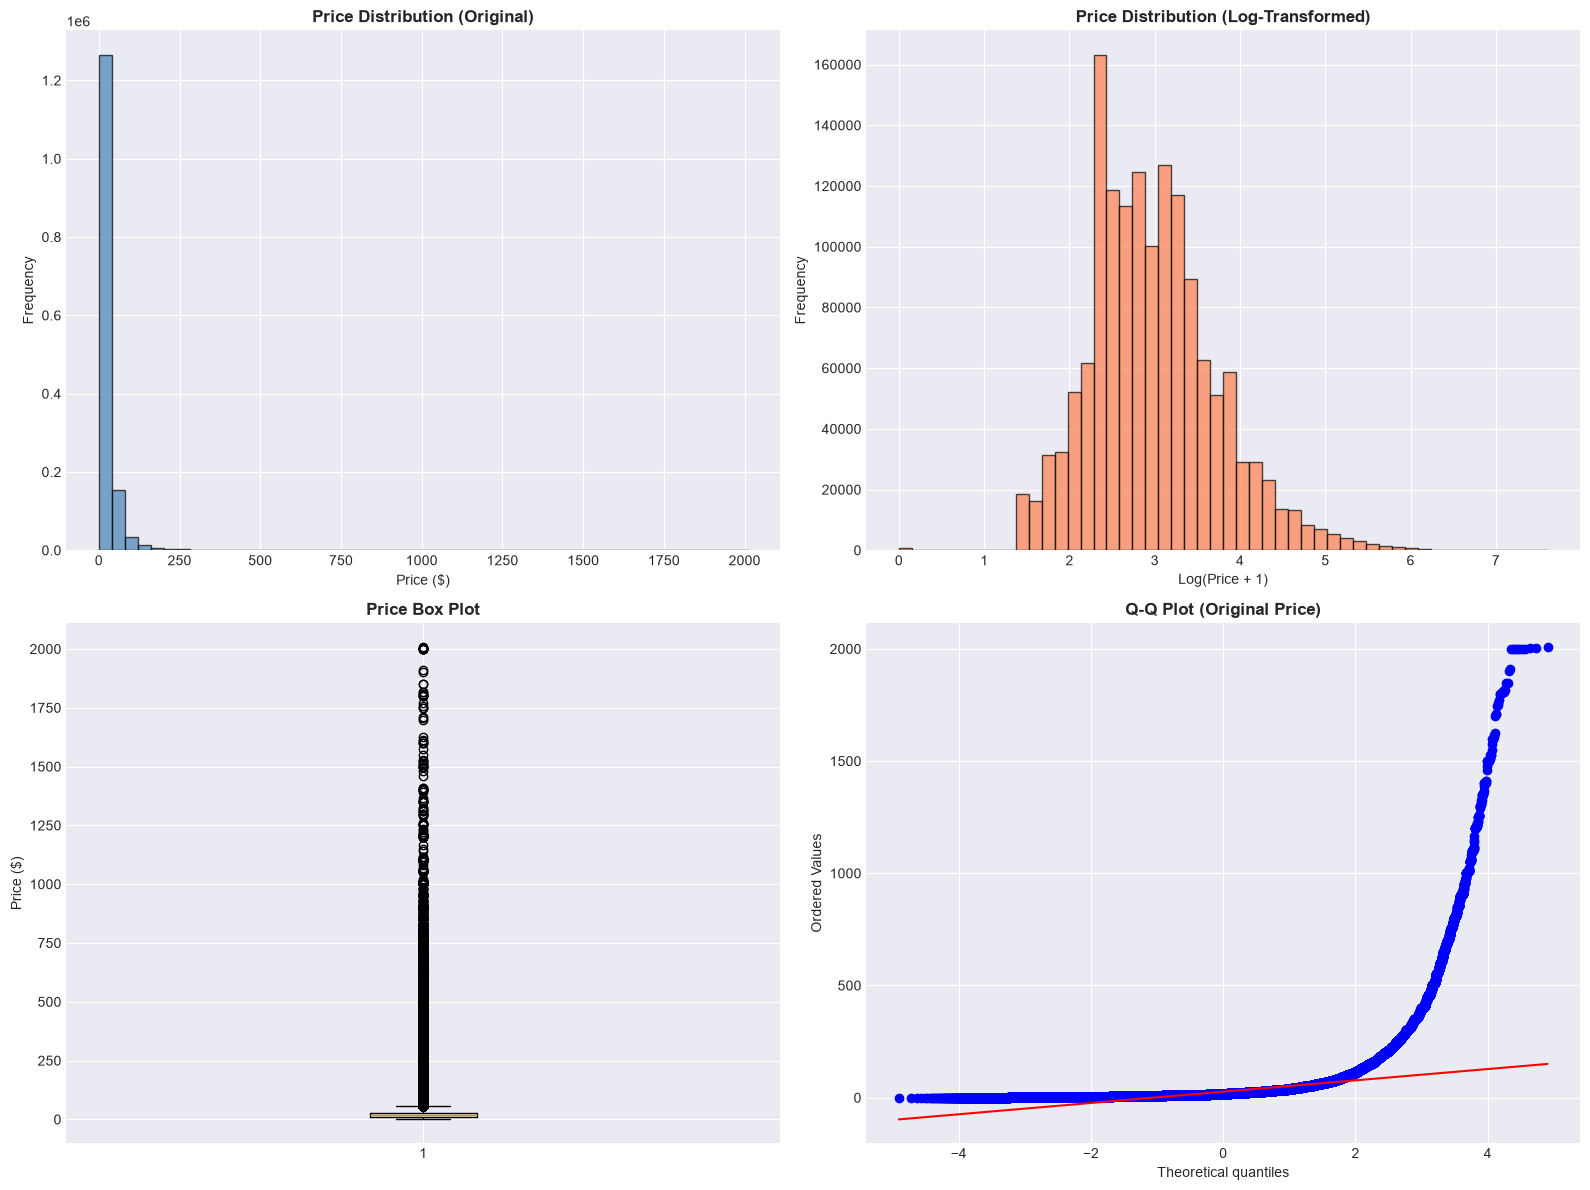

In [12]:
print("\n" + "=" * 60)
print("TARGET VARIABLE ANALYSIS - PRICE")
print("=" * 60)

target_col = 'price'

print(f"\n📊 Price Statistics:")
print(df[target_col].describe())

print(f"\n📊 Price Distribution Metrics:")
print(f"Skewness: {skew(df[target_col]):.4f}")
print(f"Kurtosis: {kurtosis(df[target_col]):.4f}")

# Visualize price distribution
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Original distribution
axes[0, 0].hist(df[target_col], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
axes[0, 0].set_title('Price Distribution (Original)', fontsize=12, fontweight='bold')
axes[0, 0].set_xlabel('Price ($)')
axes[0, 0].set_ylabel('Frequency')

# Log-transformed distribution
axes[0, 1].hist(np.log1p(df[target_col]), bins=50, color='coral', edgecolor='black', alpha=0.7)
axes[0, 1].set_title('Price Distribution (Log-Transformed)', fontsize=12, fontweight='bold')
axes[0, 1].set_xlabel('Log(Price + 1)')
axes[0, 1].set_ylabel('Frequency')

# Box plot
axes[1, 0].boxplot(df[target_col], vert=True)
axes[1, 0].set_title('Price Box Plot', fontsize=12, fontweight='bold')
axes[1, 0].set_ylabel('Price ($)')

# Q-Q Plot
stats.probplot(df[target_col], dist="norm", plot=axes[1, 1])
axes[1, 1].set_title('Q-Q Plot (Original Price)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Step 7: Outlier Detection & Analysis


OUTLIER DETECTION & ANALYSIS

📊 IQR Method:
Q1: $10.00, Q3: $29.00, IQR: $19.00
Lower Bound: $-18.50, Upper Bound: $57.50
Number of outliers: 119,352 (8.05%)

📊 Z-Score Method (|z| > 3):
Number of outliers: 21,891 (1.48%)

📊 Percentile Method (1st-99th):
1st Percentile: $3.00, 99th Percentile: $170.00
Number of outliers: 15,615 (1.05%)


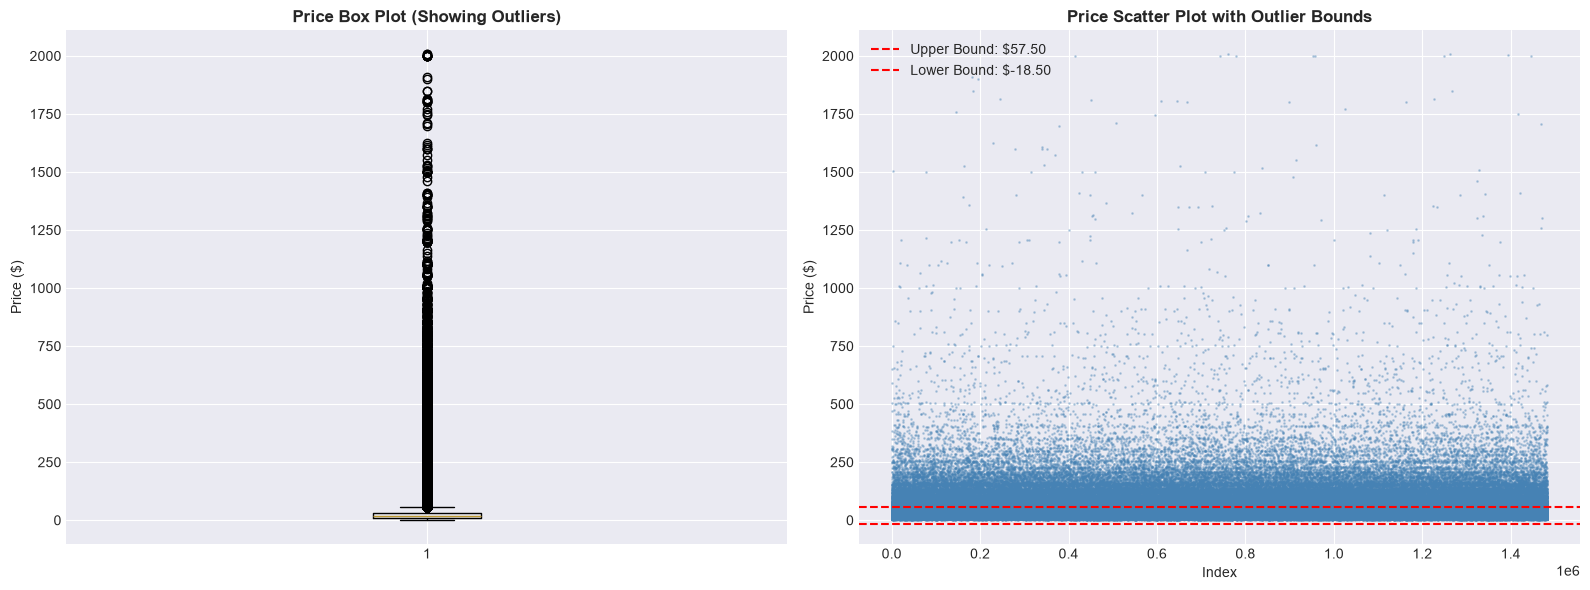

In [13]:
print("\n" + "=" * 60)
print("OUTLIER DETECTION & ANALYSIS")
print("=" * 60)

# 7.1: Statistical Outlier Detection (IQR Method)
Q1 = df[target_col].quantile(0.25)
Q3 = df[target_col].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers_iqr = df[(df[target_col] < lower_bound) | (df[target_col] > upper_bound)]
print(f"\n📊 IQR Method:")
print(f"Q1: ${Q1:.2f}, Q3: ${Q3:.2f}, IQR: ${IQR:.2f}")
print(f"Lower Bound: ${lower_bound:.2f}, Upper Bound: ${upper_bound:.2f}")
print(f"Number of outliers: {len(outliers_iqr):,} ({(len(outliers_iqr)/len(df))*100:.2f}%)")

# 7.2: Z-Score Method
z_scores = np.abs(stats.zscore(df[target_col]))
outliers_z = df[z_scores > 3]
print(f"\n📊 Z-Score Method (|z| > 3):")
print(f"Number of outliers: {len(outliers_z):,} ({(len(outliers_z)/len(df))*100:.2f}%)")

# 7.3: Percentile Method
p1 = df[target_col].quantile(0.01)
p99 = df[target_col].quantile(0.99)
outliers_percentile = df[(df[target_col] < p1) | (df[target_col] > p99)]
print(f"\n📊 Percentile Method (1st-99th):")
print(f"1st Percentile: ${p1:.2f}, 99th Percentile: ${p99:.2f}")
print(f"Number of outliers: {len(outliers_percentile):,} ({(len(outliers_percentile)/len(df))*100:.2f}%)")

# Visualize outliers
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Box plot with outliers
axes[0].boxplot(df[target_col], vert=True, whis=1.5)
axes[0].set_title('Price Box Plot (Showing Outliers)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Price ($)')

# Scatter plot of prices
axes[1].scatter(range(len(df)), df[target_col], alpha=0.3, c='steelblue', s=1)
axes[1].axhline(y=upper_bound, color='red', linestyle='--', label=f'Upper Bound: ${upper_bound:.2f}')
axes[1].axhline(y=lower_bound, color='red', linestyle='--', label=f'Lower Bound: ${lower_bound:.2f}')
axes[1].set_title('Price Scatter Plot with Outlier Bounds', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Index')
axes[1].set_ylabel('Price ($)')
axes[1].legend()

plt.tight_layout()
plt.show()

## Step 8: Univariate Analysis - Numerical Features


UNIVARIATE ANALYSIS - NUMERICAL FEATURES

📊 Numerical columns: ['train_id', 'item_condition_id', 'price', 'shipping']


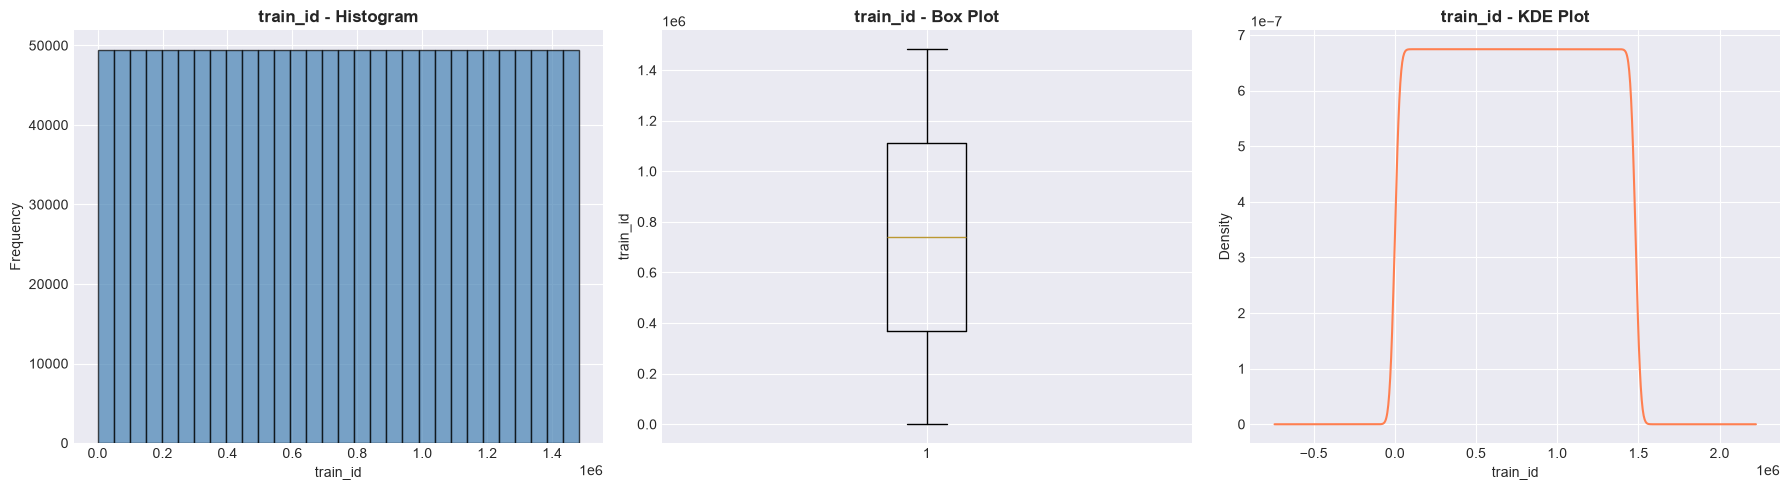


📊 train_id Statistics:
  Mean: 741267.0000
  Median: 741267.0000
  Std: 427971.1350
  Skewness: 0.0000
  Kurtosis: -1.2000


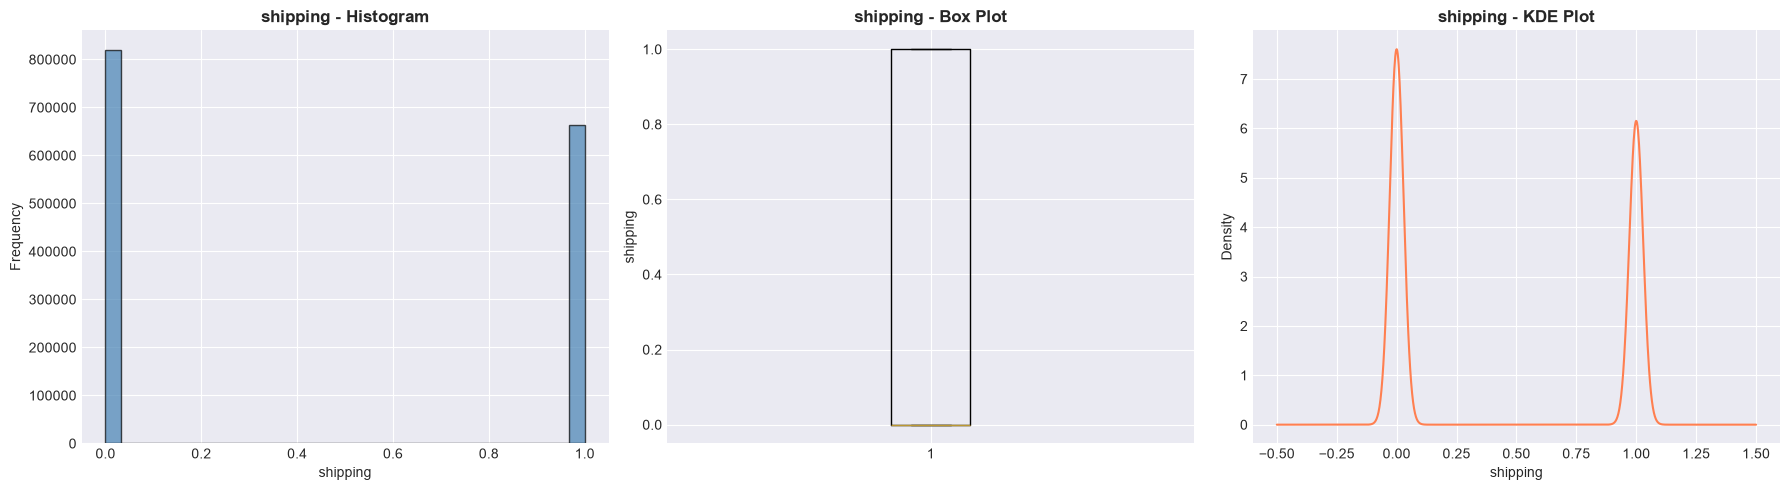


📊 shipping Statistics:
  Mean: 0.4473
  Median: 0.0000
  Std: 0.4972
  Skewness: 0.2121
  Kurtosis: -1.9550


In [14]:
print("\n" + "=" * 60)
print("UNIVARIATE ANALYSIS - NUMERICAL FEATURES")
print("=" * 60)

numerical_cols = df.select_dtypes(include=[np.number]).columns.tolist()
print(f"\n📊 Numerical columns: {numerical_cols}")

# Identify item_condition_id as categorical despite being numeric
if 'item_condition_id' in numerical_cols:
    numerical_cols.remove('item_condition_id')

for col in numerical_cols:
    if col == target_col:
        continue

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    # Histogram
    axes[0].hist(df[col].dropna(), bins=30, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0].set_title(f'{col} - Histogram', fontsize=12, fontweight='bold')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Frequency')

    # Box plot
    axes[1].boxplot(df[col].dropna(), vert=True)
    axes[1].set_title(f'{col} - Box Plot', fontsize=12, fontweight='bold')
    axes[1].set_ylabel(col)

    # KDE Plot
    df[col].dropna().plot(kind='kde', ax=axes[2], color='coral')
    axes[2].set_title(f'{col} - KDE Plot', fontsize=12, fontweight='bold')
    axes[2].set_xlabel(col)

    plt.tight_layout()
    plt.show()

    print(f"\n📊 {col} Statistics:")
    print(f"  Mean: {df[col].mean():.4f}")
    print(f"  Median: {df[col].median():.4f}")
    print(f"  Std: {df[col].std():.4f}")
    print(f"  Skewness: {skew(df[col].dropna()):.4f}")
    print(f"  Kurtosis: {kurtosis(df[col].dropna()):.4f}")

## Step 9: Univariate Analysis - Categorical Features


UNIVARIATE ANALYSIS - CATEGORICAL FEATURES

📊 Categorical columns: ['name', 'category_name', 'brand_name', 'item_description', 'item_condition_id']

ANALYZING: name

📊 Top 10 Values:
name
Bundle                 2232
Reserved                453
Converse                445
BUNDLE                  418
Dress                   410
Coach purse             404
Lularoe TC leggings     396
Romper                  353
Nike                    340
Vans                    334
Name: count, dtype: int64

📊 Unique Values: 1225273
📊 Missing Values: 0 (0.00%)


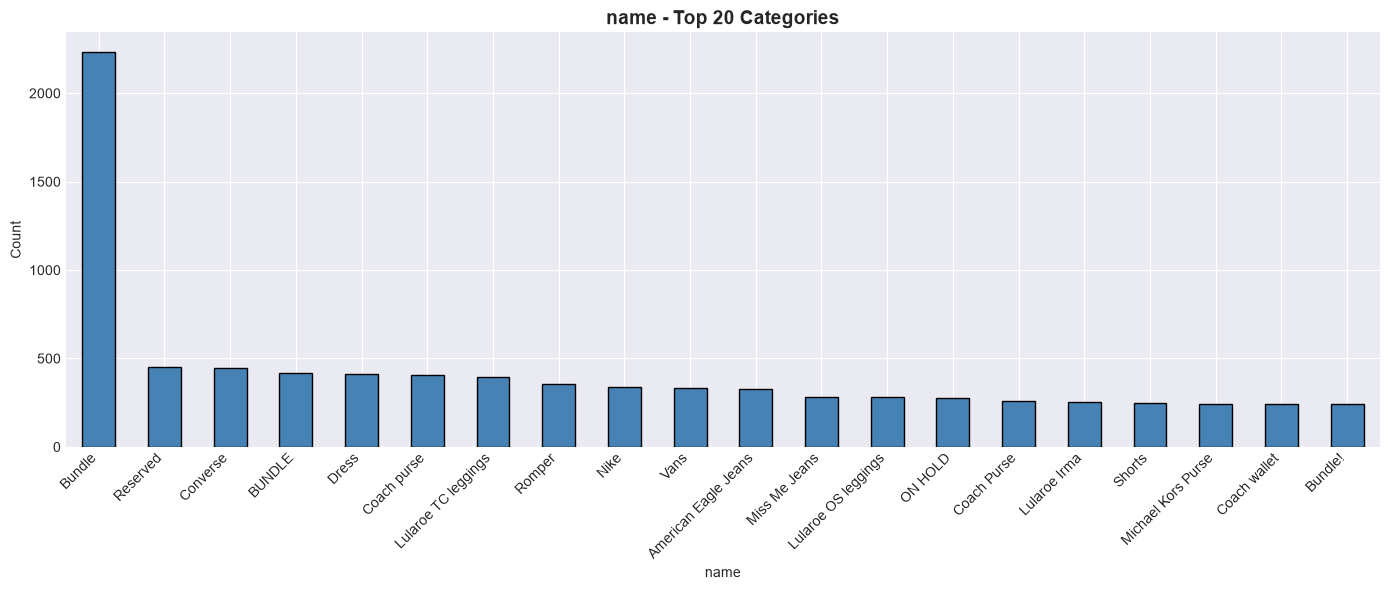


ANALYZING: category_name

📊 Top 10 Values:
category_name
Women/Athletic Apparel/Pants, Tights, Leggings                 60177
Women/Tops & Blouses/T-Shirts                                  46380
Beauty/Makeup/Face                                             34335
Beauty/Makeup/Lips                                             29910
Electronics/Video Games & Consoles/Games                       26557
Beauty/Makeup/Eyes                                             25215
Electronics/Cell Phones & Accessories/Cases, Covers & Skins    24676
Women/Underwear/Bras                                           21274
Women/Tops & Blouses/Blouse                                    20284
Women/Tops & Blouses/Tank, Cami                                20284
Name: count, dtype: int64

📊 Unique Values: 1287
📊 Missing Values: 6,327 (0.43%)


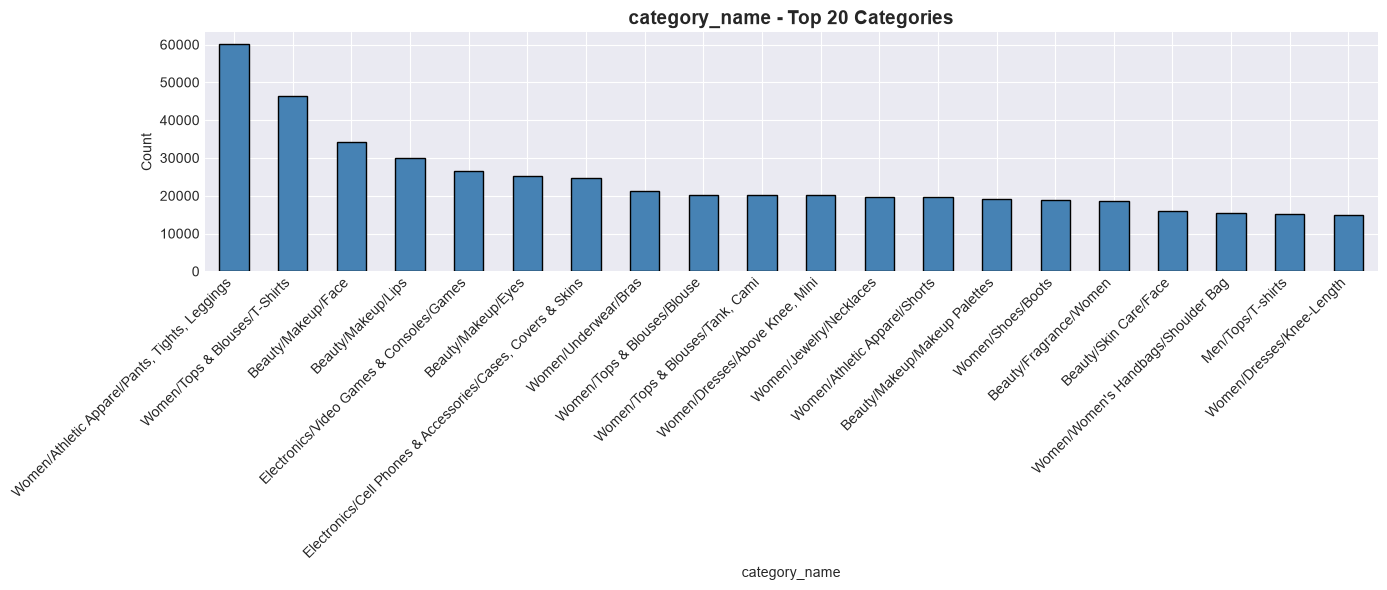


ANALYZING: brand_name

📊 Top 10 Values:
brand_name
PINK                 54088
Nike                 54043
Victoria's Secret    48036
LuLaRoe              31024
Apple                17322
FOREVER 21           15186
Nintendo             15007
Lululemon            14558
Michael Kors         13928
American Eagle       13254
Name: count, dtype: int64

📊 Unique Values: 4809
📊 Missing Values: 632,682 (42.68%)


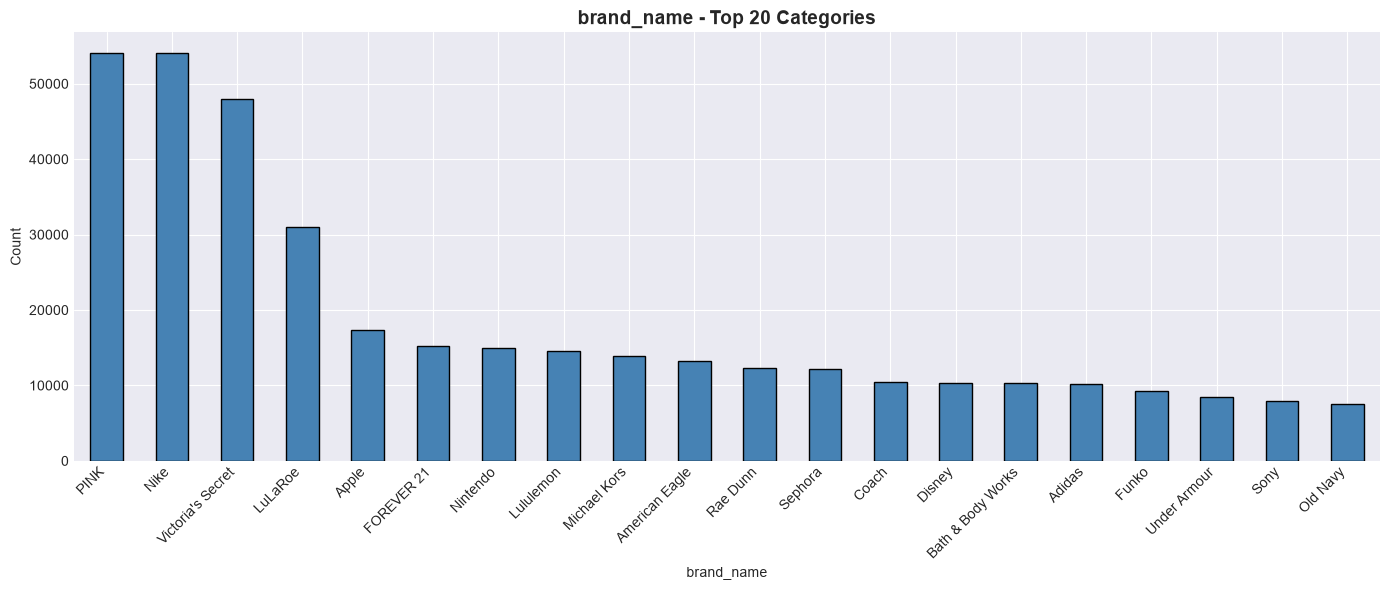


ANALYZING: item_description

📊 Top 10 Values:
item_description
No description yet    82489
New                    4099
Brand new              3058
Good condition         1274
Great condition        1158
Like new                987
Never worn              837
NWT                     822
New with tags           644
Never used              605
Name: count, dtype: int64

📊 Unique Values: 1281423
📊 Missing Values: 6 (0.00%)


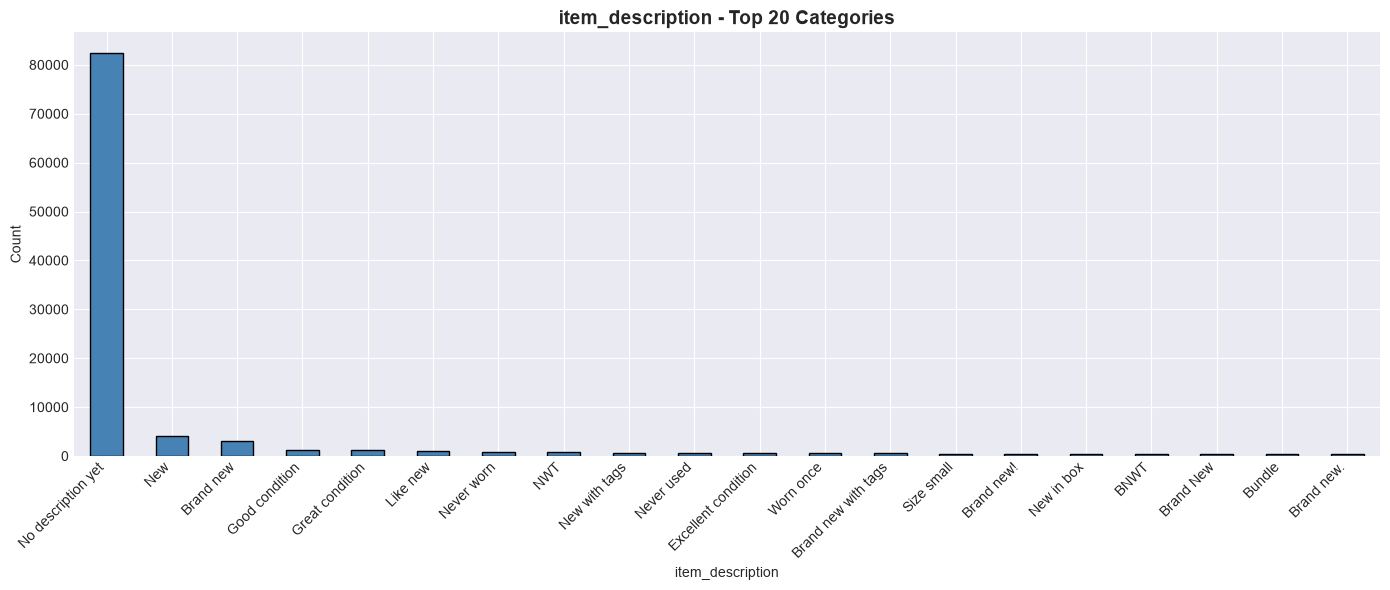


ANALYZING: item_condition_id

📊 Top 10 Values:
item_condition_id
1    640549
3    432161
2    375479
4     31962
5      2384
Name: count, dtype: int64

📊 Unique Values: 5
📊 Missing Values: 0 (0.00%)


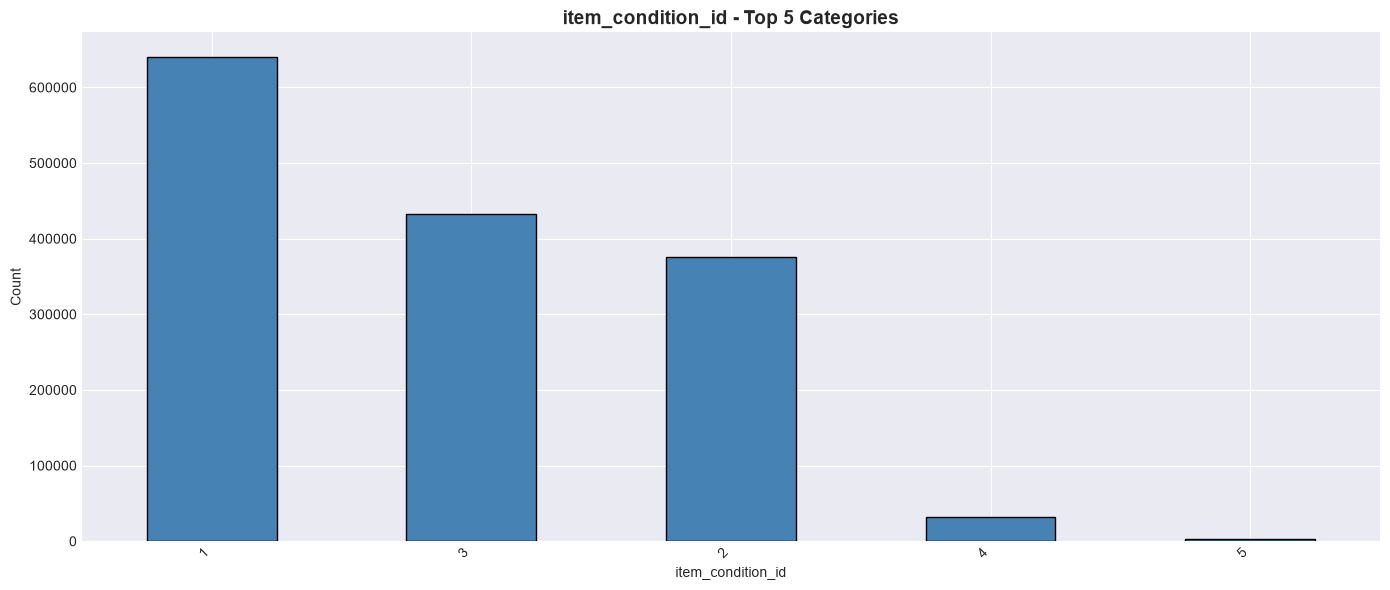

In [15]:
print("\n" + "=" * 60)
print("UNIVARIATE ANALYSIS - CATEGORICAL FEATURES")
print("=" * 60)

categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
if 'item_condition_id' in df.columns:
    categorical_cols.append('item_condition_id')

print(f"\n📊 Categorical columns: {categorical_cols}")

for col in categorical_cols:
    print(f"\n{'='*60}")
    print(f"ANALYZING: {col}")
    print(f"{'='*60}")

    # Value counts
    value_counts = df[col].value_counts()
    print(f"\n📊 Top 10 Values:")
    print(value_counts.head(10))

    print(f"\n📊 Unique Values: {df[col].nunique()}")
    print(f"📊 Missing Values: {df[col].isnull().sum():,} ({(df[col].isnull().sum()/len(df))*100:.2f}%)")

    # Visualize top categories
    plt.figure(figsize=(14, 6))
    top_n = min(20, len(value_counts))
    value_counts.head(top_n).plot(kind='bar', color='steelblue', edgecolor='black')
    plt.title(f'{col} - Top {top_n} Categories', fontsize=14, fontweight='bold')
    plt.xlabel(col)
    plt.ylabel('Count')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

## Step 10: Bivariate Analysis - Price Vs Numerical Features


BIVARIATE ANALYSIS - PRICE vs NUMERICAL FEATURES


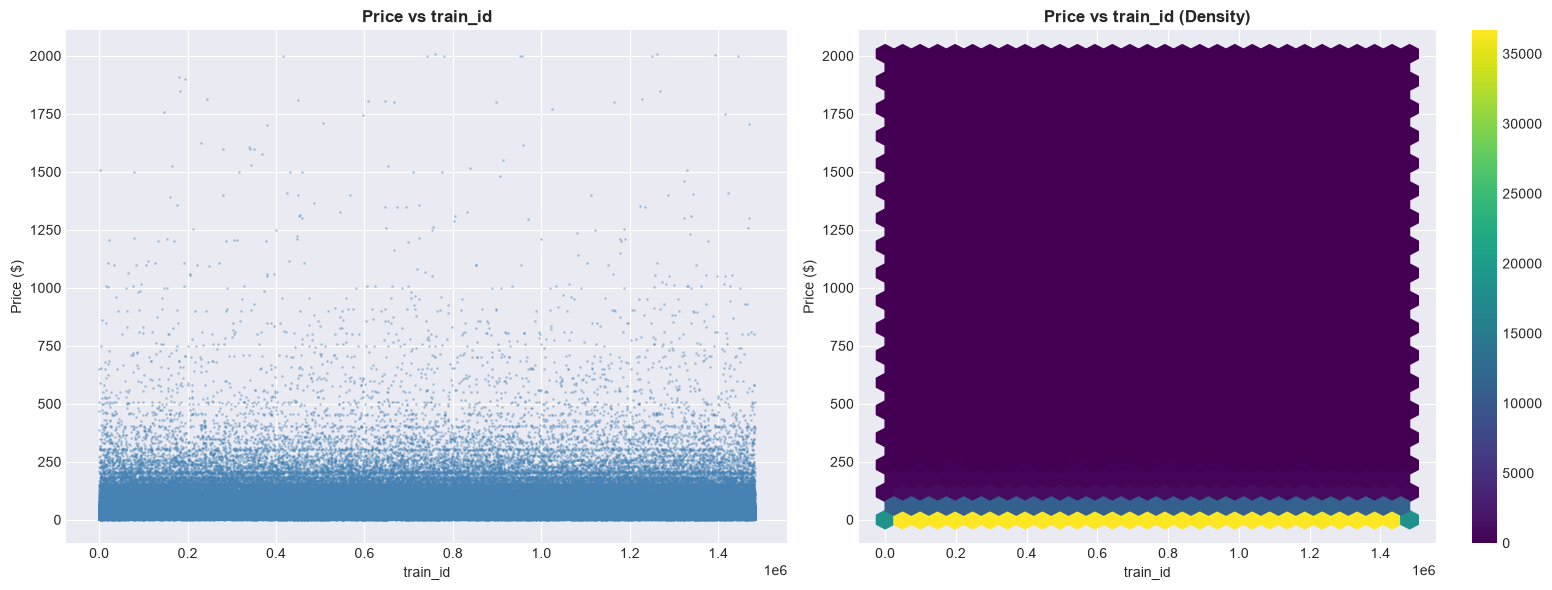


📊 Correlation between train_id and Price: 0.0005


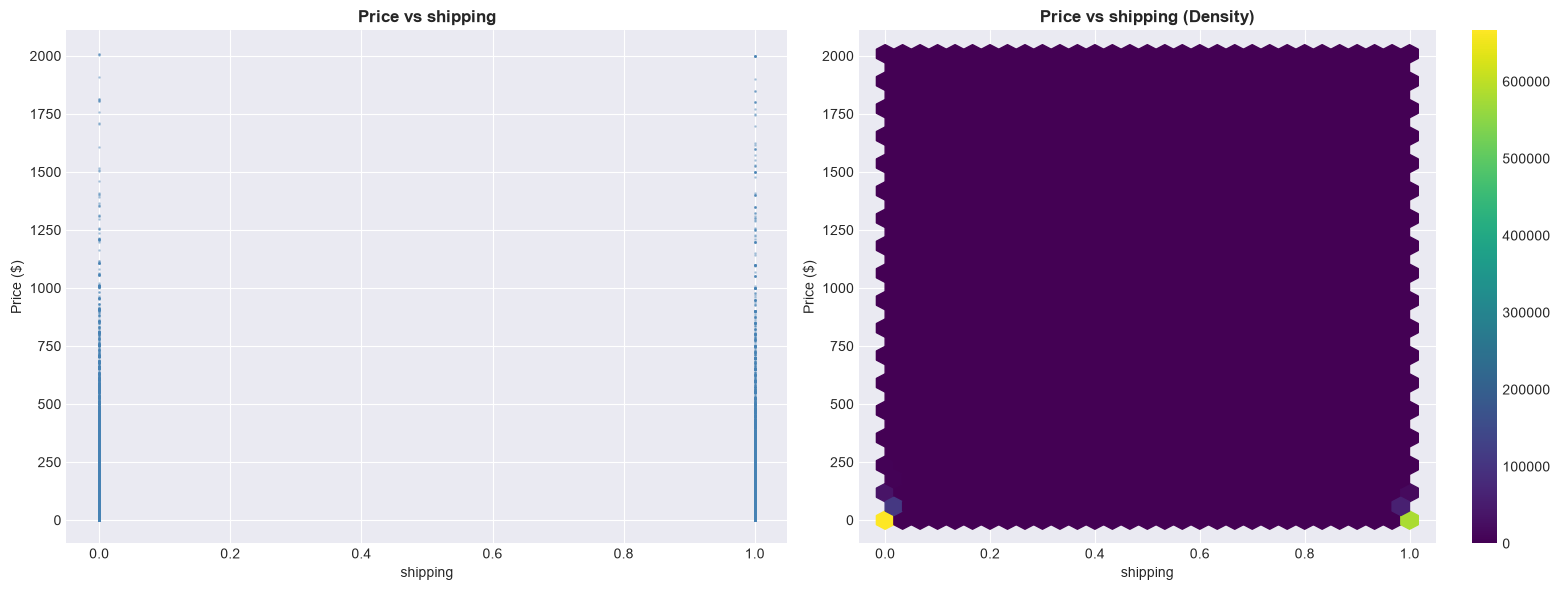


📊 Correlation between shipping and Price: -0.0972


In [16]:
print("\n" + "=" * 60)
print("BIVARIATE ANALYSIS - PRICE vs NUMERICAL FEATURES")
print("=" * 60)

for col in numerical_cols:
    if col == target_col:
        continue

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Scatter plot
    axes[0].scatter(df[col], df[target_col], alpha=0.3, c='steelblue', s=1)
    axes[0].set_title(f'Price vs {col}', fontsize=12, fontweight='bold')
    axes[0].set_xlabel(col)
    axes[0].set_ylabel('Price ($)')

    # Hexbin plot for density
    hb = axes[1].hexbin(df[col], df[target_col], gridsize=30, cmap='viridis')
    axes[1].set_title(f'Price vs {col} (Density)', fontsize=12, fontweight='bold')
    axes[1].set_xlabel(col)
    axes[1].set_ylabel('Price ($)')
    plt.colorbar(hb, ax=axes[1])

    plt.tight_layout()
    plt.show()

    # Correlation
    correlation = df[col].corr(df[target_col])
    print(f"\n📊 Correlation between {col} and Price: {correlation:.4f}")

## Step 11: Bivariate Analysis - Price Vs Categorical Features


BIVARIATE ANALYSIS - PRICE vs CATEGORICAL FEATURES

📊 Price by Item Condition:
                        mean  median        std   count
item_condition_id                                      
1                  26.486967    18.0  35.418024  640549
2                  27.563225    17.0  42.125698  375479
3                  26.540711    16.0  40.030681  432161
4                  24.349212    15.0  35.679148   31962
5                  31.703859    19.0  39.531069    2384


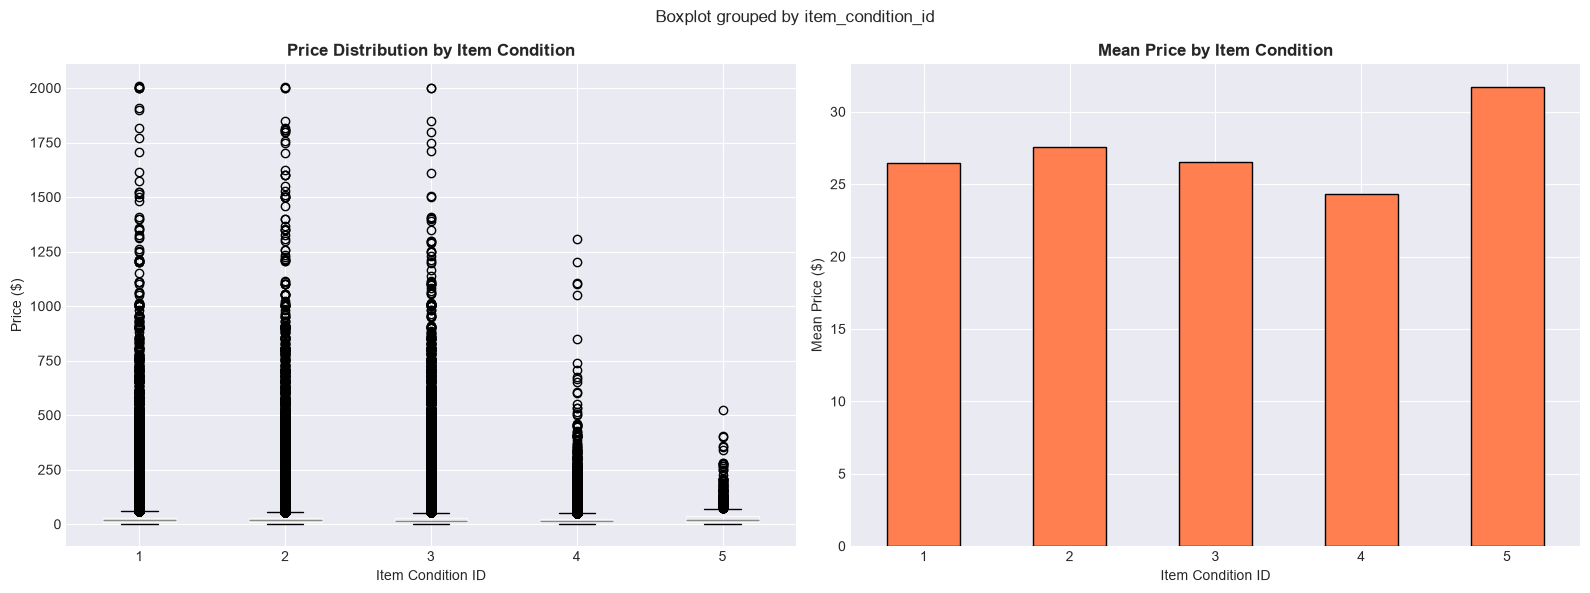


📊 Price by Shipping:
               mean  median       std   count
shipping                                     
0         30.111778    20.0  39.53592  819435
1         22.567726    14.0  36.95579  663100


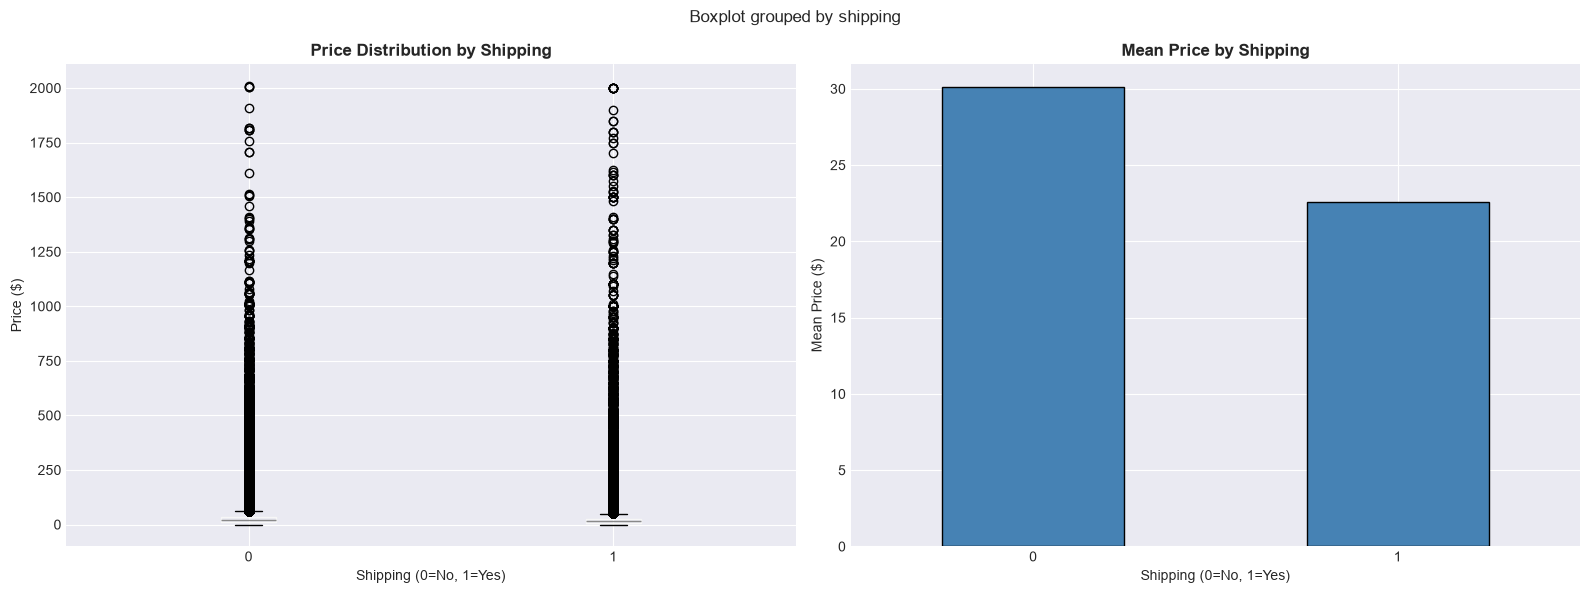

In [17]:
print("\n" + "=" * 60)
print("BIVARIATE ANALYSIS - PRICE vs CATEGORICAL FEATURES")
print("=" * 60)

# Item Condition vs Price
if 'item_condition_id' in df.columns:
    print("\n📊 Price by Item Condition:")
    condition_price = df.groupby('item_condition_id')[target_col].agg(['mean', 'median', 'std', 'count'])
    print(condition_price)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Box plot
    df.boxplot(column=target_col, by='item_condition_id', ax=axes[0])
    axes[0].set_title('Price Distribution by Item Condition', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Item Condition ID')
    axes[0].set_ylabel('Price ($)')

    # Bar plot of mean prices
    condition_price['mean'].plot(kind='bar', ax=axes[1], color='coral', edgecolor='black')
    axes[1].set_title('Mean Price by Item Condition', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Item Condition ID')
    axes[1].set_ylabel('Mean Price ($)')
    axes[1].tick_params(axis='x', rotation=0)

    plt.tight_layout()
    plt.show()

# Shipping vs Price
if 'shipping' in df.columns:
    print("\n📊 Price by Shipping:")
    shipping_price = df.groupby('shipping')[target_col].agg(['mean', 'median', 'std', 'count'])
    print(shipping_price)

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    # Box plot
    df.boxplot(column=target_col, by='shipping', ax=axes[0])
    axes[0].set_title('Price Distribution by Shipping', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Shipping (0=No, 1=Yes)')
    axes[0].set_ylabel('Price ($)')

    # Bar plot
    shipping_price['mean'].plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
    axes[1].set_title('Mean Price by Shipping', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Shipping (0=No, 1=Yes)')
    axes[1].set_ylabel('Mean Price ($)')
    axes[1].tick_params(axis='x', rotation=0)

    plt.tight_layout()
    plt.show()

## Step 12: Text Features Analysis


TEXT FEATURES ANALYSIS

ANALYZING TEXT FEATURE: name

📊 Text Length Statistics:
count    1.482535e+06
mean     2.578640e+01
std      9.164533e+00
min      1.000000e+00
25%      1.900000e+01
50%      2.600000e+01
75%      3.400000e+01
max      4.300000e+01
Name: name_length, dtype: float64

📊 Word Count Statistics:
count    1.482535e+06
mean     4.400867e+00
std      1.654776e+00
min      1.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      6.000000e+00
max      1.700000e+01
Name: name_word_count, dtype: float64


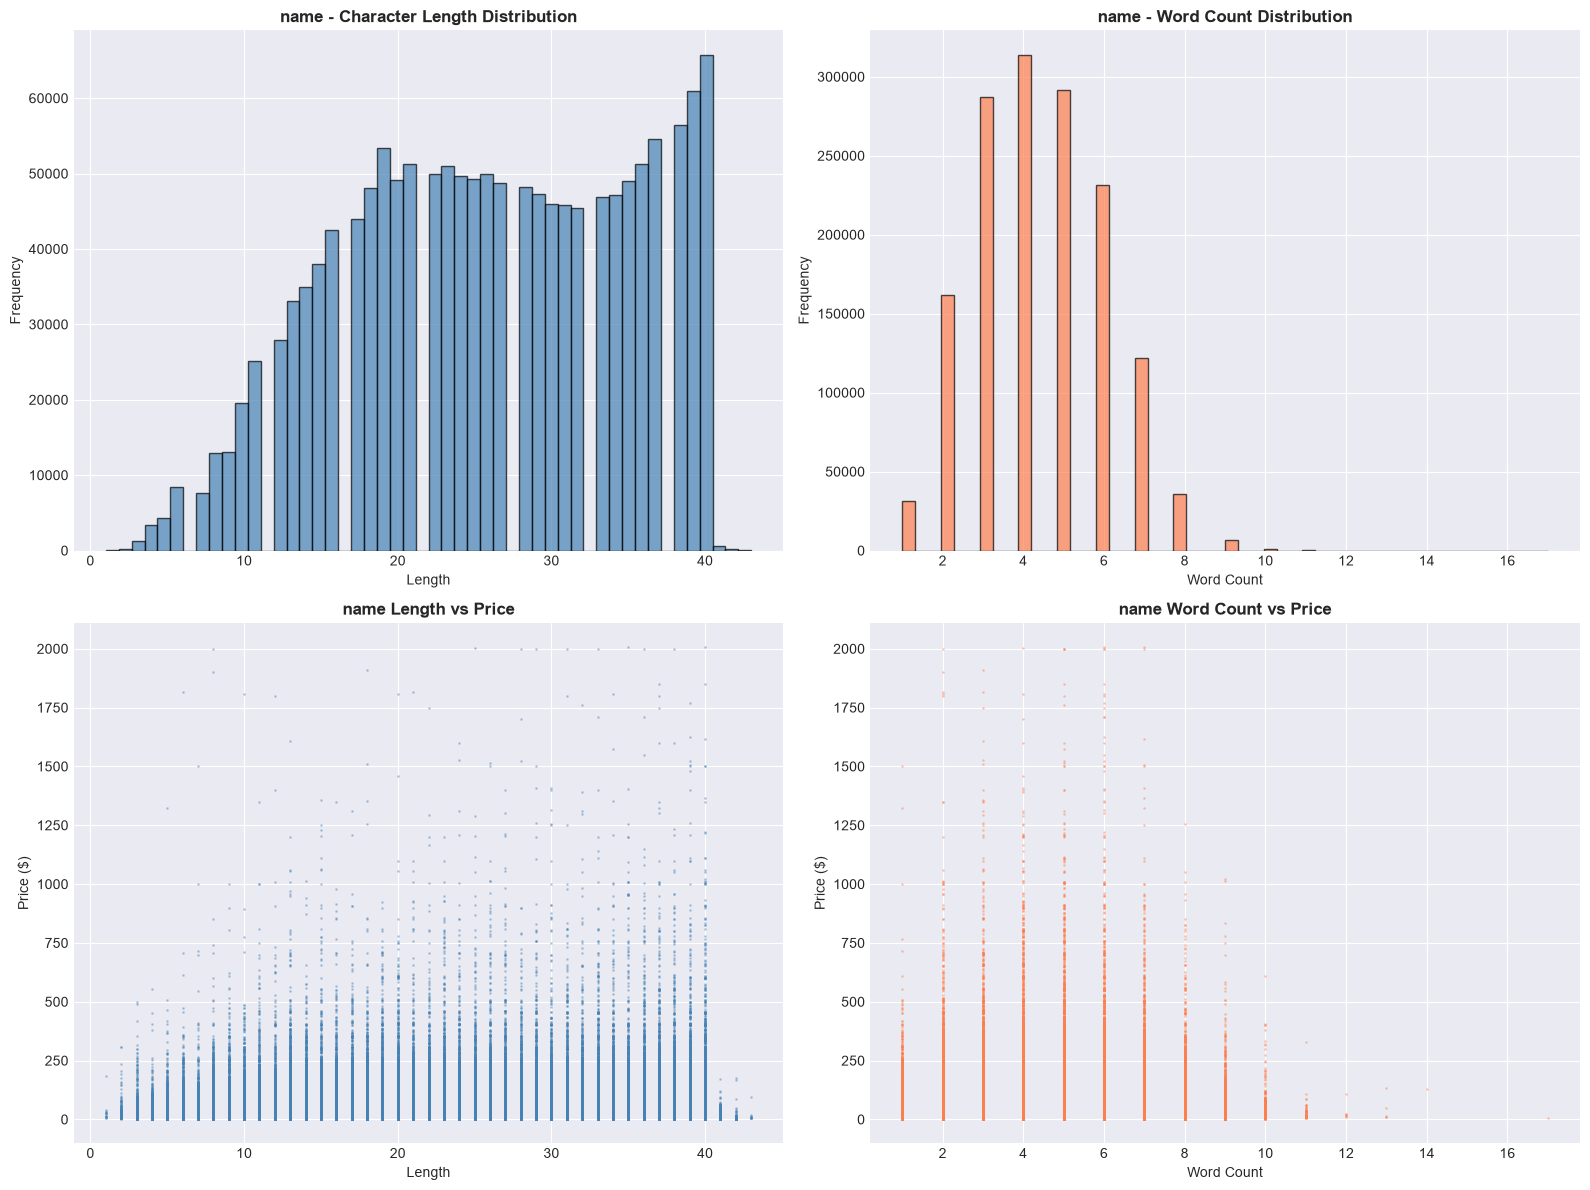


📊 Correlation with Price:
  Length: 0.0271
  Word Count: 0.0345

ANALYZING TEXT FEATURE: item_description

📊 Text Length Statistics:
count    1.482535e+06
mean     1.457074e+02
std      1.744369e+02
min      0.000000e+00
25%      4.000000e+01
50%      8.600000e+01
75%      1.740000e+02
max      1.046000e+03
Name: item_description_length, dtype: float64

📊 Word Count Statistics:
count    1.482535e+06
mean     2.568779e+01
std      3.039124e+01
min      0.000000e+00
25%      7.000000e+00
50%      1.500000e+01
75%      3.100000e+01
max      2.450000e+02
Name: item_description_word_count, dtype: float64


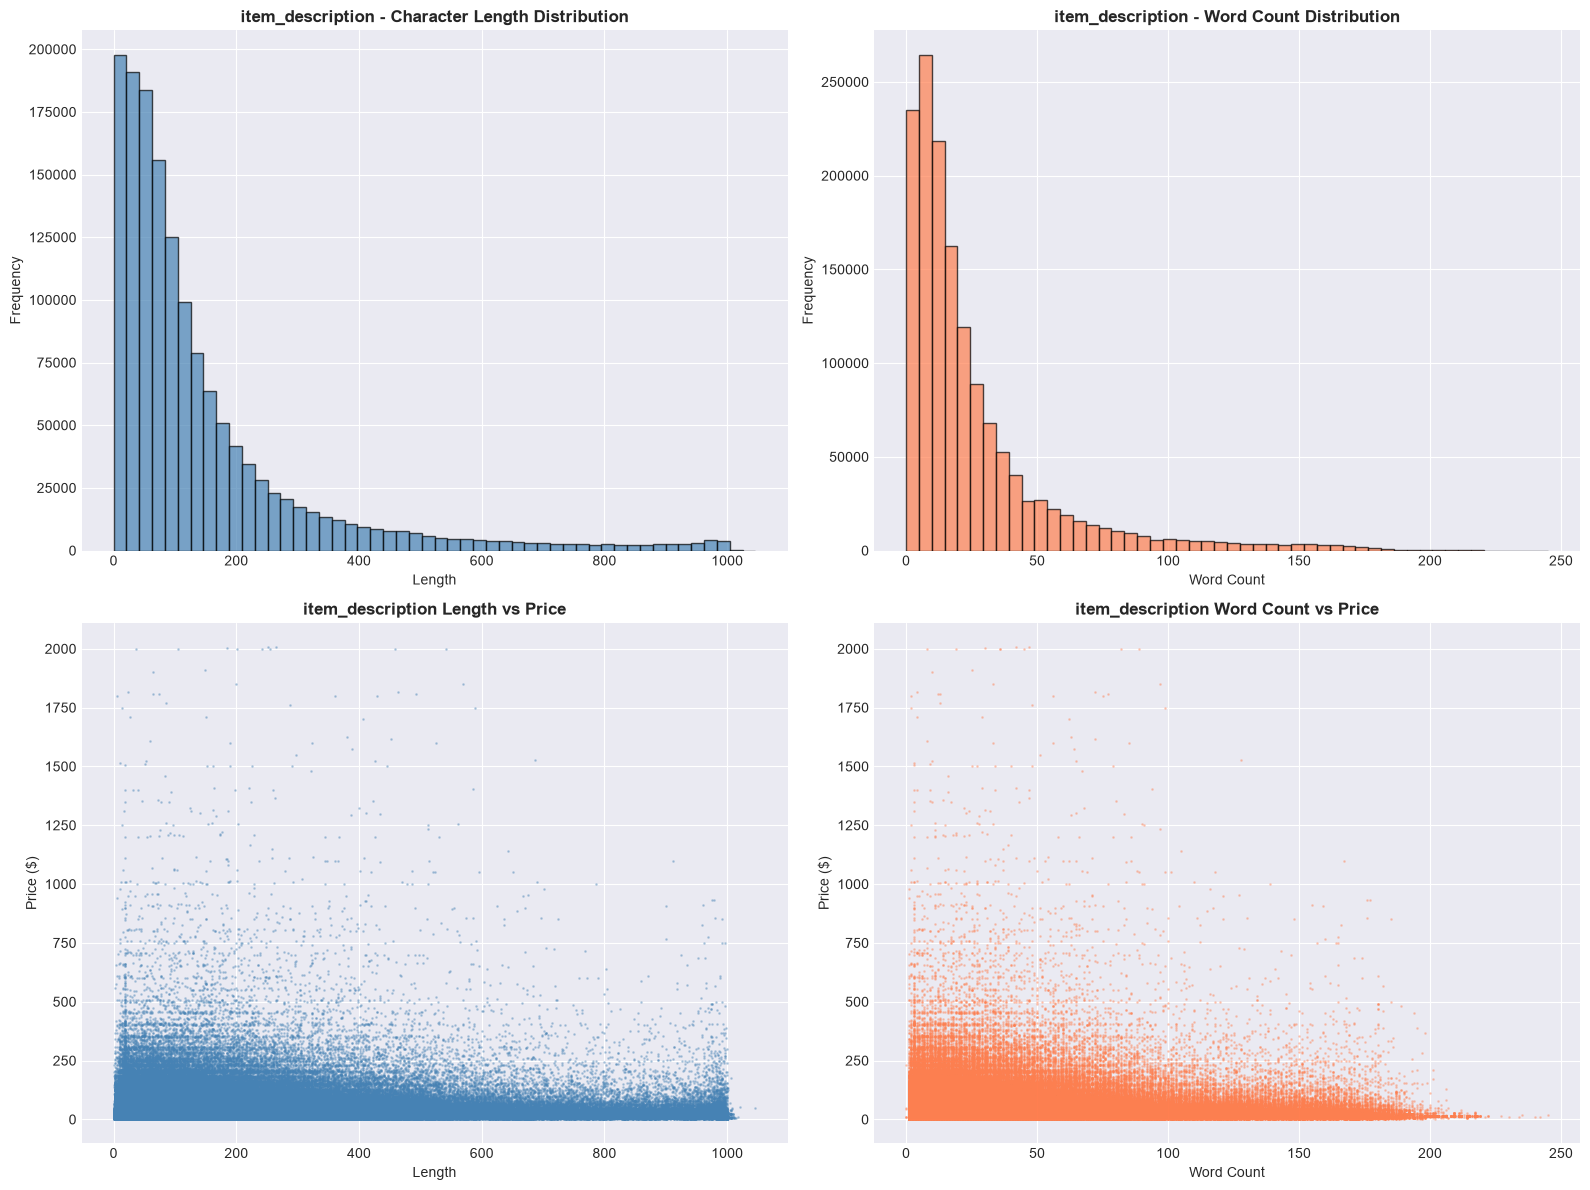


📊 Correlation with Price:
  Length: 0.0480
  Word Count: 0.0486


In [18]:
print("\n" + "=" * 60)
print("TEXT FEATURES ANALYSIS")
print("=" * 60)

text_columns = ['name', 'item_description']

for col in text_columns:
    if col not in df.columns:
        continue

    print(f"\n{'='*60}")
    print(f"ANALYZING TEXT FEATURE: {col}")
    print(f"{'='*60}")

    # Calculate text lengths
    df[f'{col}_length'] = df[col].fillna('').astype(str).apply(len)
    df[f'{col}_word_count'] = df[col].fillna('').astype(str).apply(lambda x: len(x.split()))

    print(f"\n📊 Text Length Statistics:")
    print(df[f'{col}_length'].describe())

    print(f"\n📊 Word Count Statistics:")
    print(df[f'{col}_word_count'].describe())

    # Visualize text length distribution
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))

    # Length histogram
    axes[0, 0].hist(df[f'{col}_length'], bins=50, color='steelblue', edgecolor='black', alpha=0.7)
    axes[0, 0].set_title(f'{col} - Character Length Distribution', fontsize=12, fontweight='bold')
    axes[0, 0].set_xlabel('Length')
    axes[0, 0].set_ylabel('Frequency')

    # Word count histogram
    axes[0, 1].hist(df[f'{col}_word_count'], bins=50, color='coral', edgecolor='black', alpha=0.7)
    axes[0, 1].set_title(f'{col} - Word Count Distribution', fontsize=12, fontweight='bold')
    axes[0, 1].set_xlabel('Word Count')
    axes[0, 1].set_ylabel('Frequency')

    # Length vs Price
    axes[1, 0].scatter(df[f'{col}_length'], df[target_col], alpha=0.3, c='steelblue', s=1)
    axes[1, 0].set_title(f'{col} Length vs Price', fontsize=12, fontweight='bold')
    axes[1, 0].set_xlabel('Length')
    axes[1, 0].set_ylabel('Price ($)')

    # Word count vs Price
    axes[1, 1].scatter(df[f'{col}_word_count'], df[target_col], alpha=0.3, c='coral', s=1)
    axes[1, 1].set_title(f'{col} Word Count vs Price', fontsize=12, fontweight='bold')
    axes[1, 1].set_xlabel('Word Count')
    axes[1, 1].set_ylabel('Price ($)')

    plt.tight_layout()
    plt.show()

    # Correlation with price
    length_corr = df[f'{col}_length'].corr(df[target_col])
    word_corr = df[f'{col}_word_count'].corr(df[target_col])
    print(f"\n📊 Correlation with Price:")
    print(f"  Length: {length_corr:.4f}")
    print(f"  Word Count: {word_corr:.4f}")

## Step 13: Category Analysis (Brand, Category, Etc.)


CATEGORY FEATURES ANALYSIS

📊 BRAND ANALYSIS:
Total unique brands: 4809
Missing brands: 632,682 (42.68%)

Top 20 Brands:
brand_name
PINK                 54088
Nike                 54043
Victoria's Secret    48036
LuLaRoe              31024
Apple                17322
FOREVER 21           15186
Nintendo             15007
Lululemon            14558
Michael Kors         13928
American Eagle       13254
Rae Dunn             12305
Sephora              12172
Coach                10463
Disney               10360
Bath & Body Works    10354
Adidas               10202
Funko                 9237
Under Armour          8461
Sony                  7994
Old Navy              7567
Name: count, dtype: int64


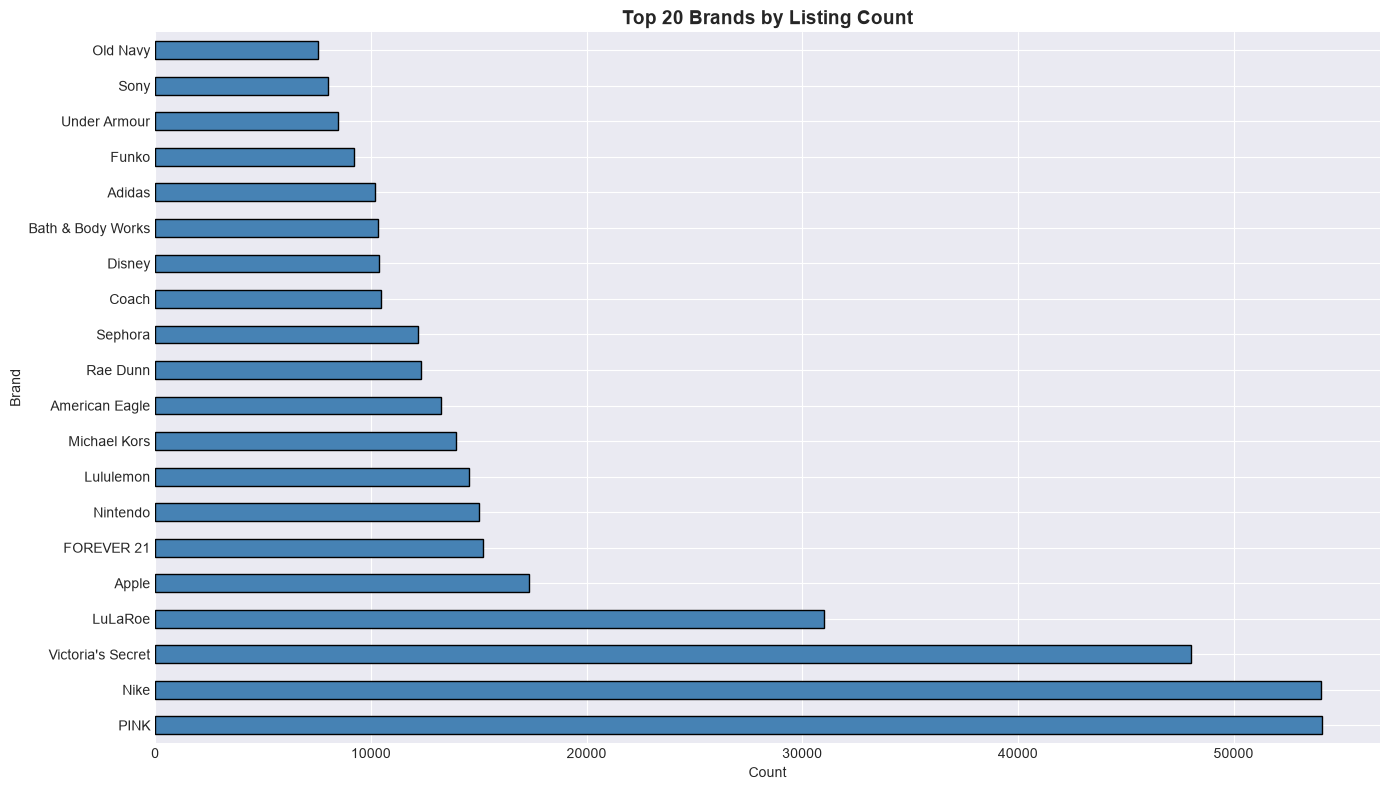

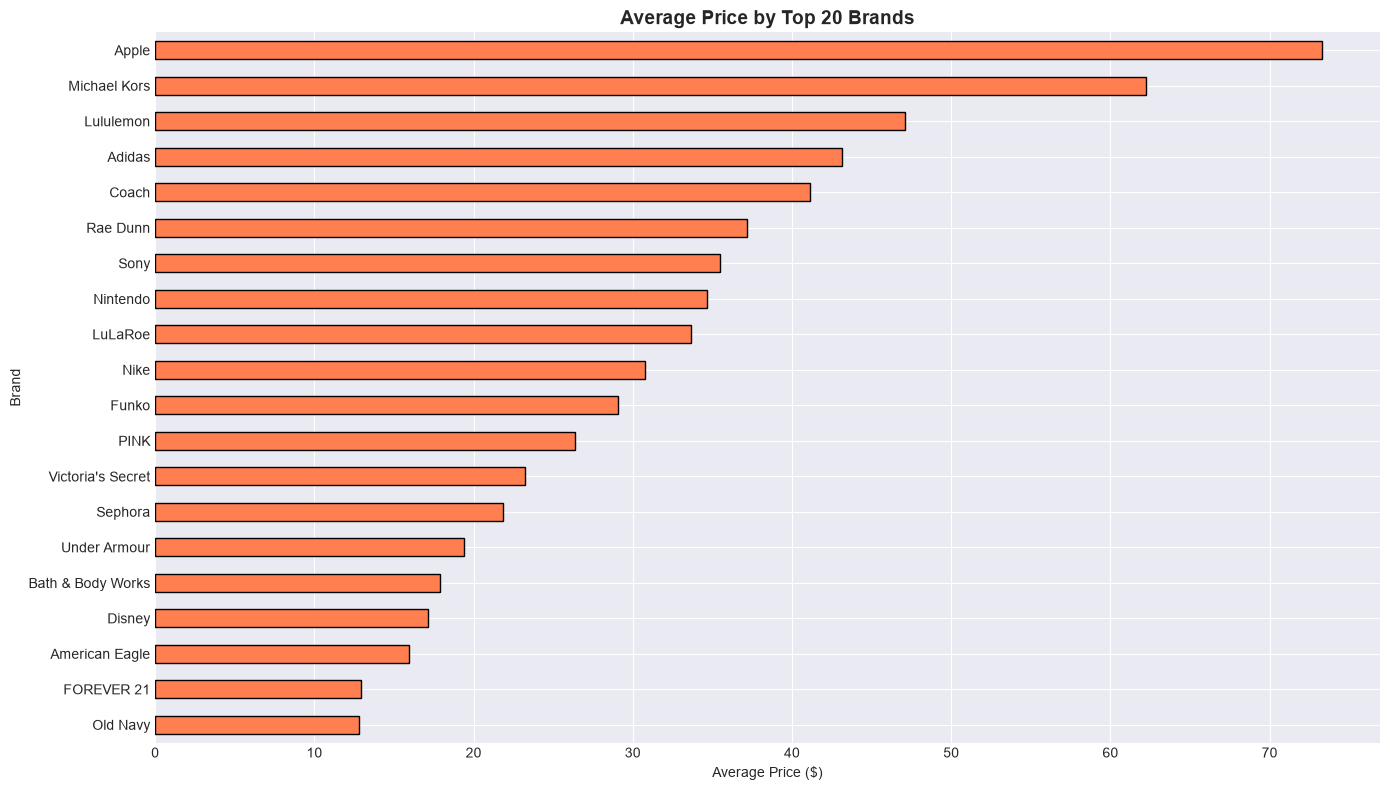


📊 CATEGORY ANALYSIS:
Total unique categories: 1287
Missing categories: 6,327 (0.43%)

Top 20 Main Categories:
category_1
Women                     664385
Beauty                    207828
Kids                      171689
Electronics               122690
Men                        93680
Home                       67871
Vintage & Collectibles     46530
Other                      45351
Handmade                   30842
Sports & Outdoors          25342
                            6327
Name: count, dtype: int64


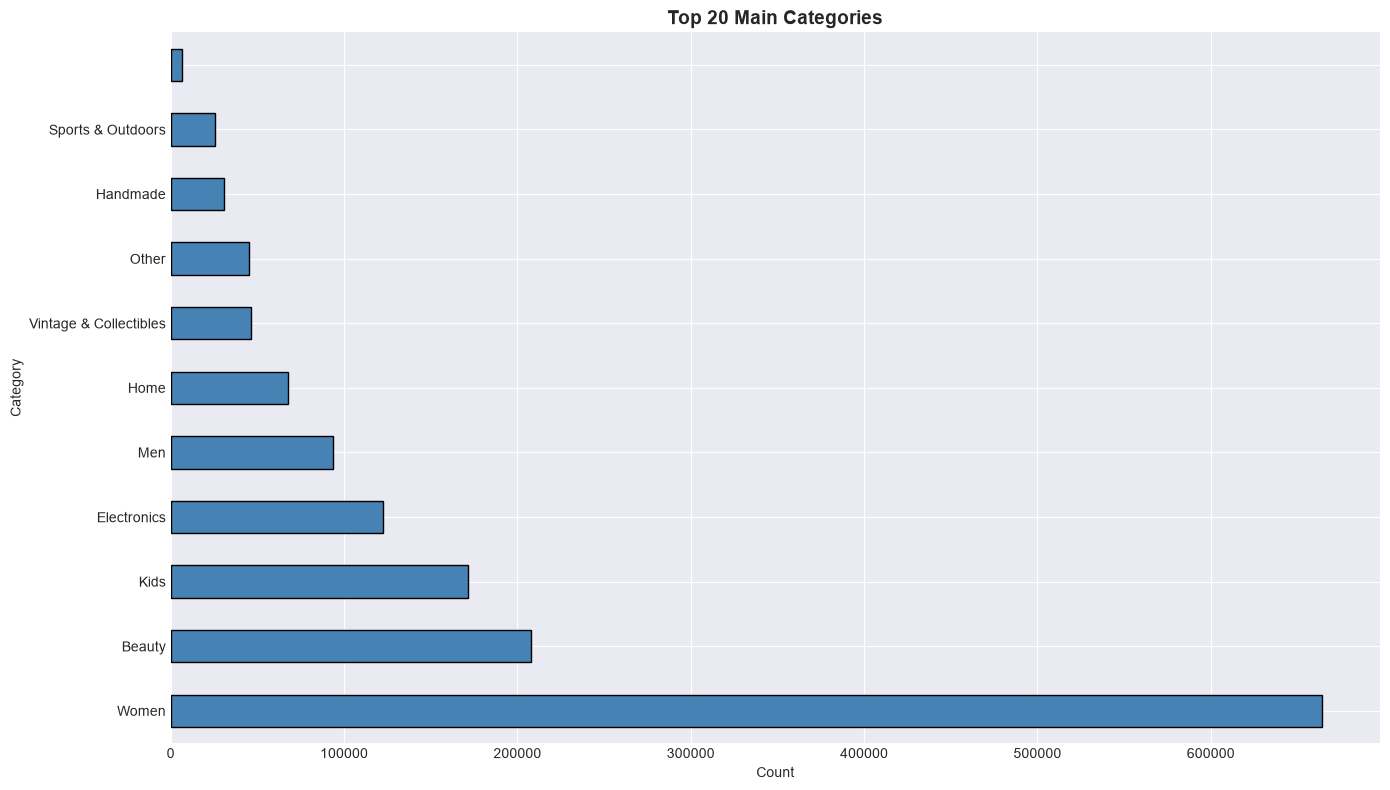

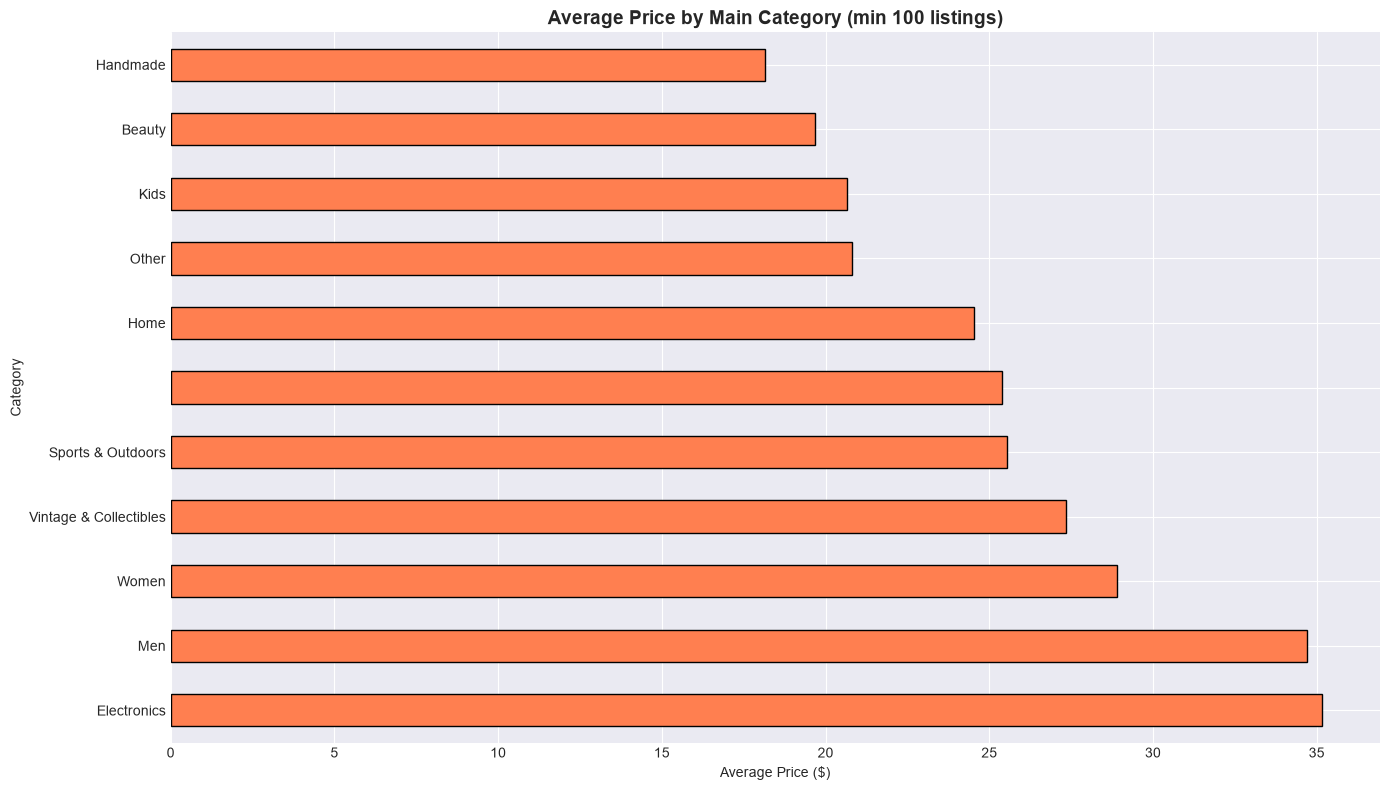

In [19]:
print("\n" + "=" * 60)
print("CATEGORY FEATURES ANALYSIS")
print("=" * 60)

# Brand Analysis
if 'brand_name' in df.columns:
    print("\n📊 BRAND ANALYSIS:")
    brand_counts = df['brand_name'].value_counts()
    print(f"Total unique brands: {df['brand_name'].nunique()}")
    print(f"Missing brands: {df['brand_name'].isnull().sum():,} ({(df['brand_name'].isnull().sum()/len(df))*100:.2f}%)")

    print("\nTop 20 Brands:")
    print(brand_counts.head(20))

    # Top brands by count
    plt.figure(figsize=(14, 8))
    top_brands = brand_counts.head(20)
    top_brands.plot(kind='barh', color='steelblue', edgecolor='black')
    plt.title('Top 20 Brands by Listing Count', fontsize=14, fontweight='bold')
    plt.xlabel('Count')
    plt.ylabel('Brand')
    plt.tight_layout()
    plt.show()

    # Average price by top brands
    top_brand_names = top_brands.index.tolist()
    brand_prices = df[df['brand_name'].isin(top_brand_names)].groupby('brand_name')[target_col].mean().sort_values()

    plt.figure(figsize=(14, 8))
    brand_prices.plot(kind='barh', color='coral', edgecolor='black')
    plt.title('Average Price by Top 20 Brands', fontsize=14, fontweight='bold')
    plt.xlabel('Average Price ($)')
    plt.ylabel('Brand')
    plt.tight_layout()
    plt.show()

# Category Analysis
if 'category_name' in df.columns:
    print("\n📊 CATEGORY ANALYSIS:")
    print(f"Total unique categories: {df['category_name'].nunique()}")
    print(f"Missing categories: {df['category_name'].isnull().sum():,} ({(df['category_name'].isnull().sum()/len(df))*100:.2f}%)")

    # Split category into subcategories
    df['category_1'] = df['category_name'].fillna('').astype(str).apply(lambda x: x.split('/')[0] if '/' in x else x)
    df['category_2'] = df['category_name'].fillna('').astype(str).apply(lambda x: x.split('/')[1] if len(x.split('/')) > 1 else '')
    df['category_3'] = df['category_name'].fillna('').astype(str).apply(lambda x: x.split('/')[2] if len(x.split('/')) > 2 else '')

    print("\nTop 20 Main Categories:")
    print(df['category_1'].value_counts().head(20))

    # Visualize main categories
    plt.figure(figsize=(14, 8))
    df['category_1'].value_counts().head(20).plot(kind='barh', color='steelblue', edgecolor='black')
    plt.title('Top 20 Main Categories', fontsize=14, fontweight='bold')
    plt.xlabel('Count')
    plt.ylabel('Category')
    plt.tight_layout()
    plt.show()

    # Average price by main category
    cat_prices = df.groupby('category_1')[target_col].agg(['mean', 'median', 'count'])
    cat_prices = cat_prices[cat_prices['count'] > 100].sort_values('mean', ascending=False).head(20)

    plt.figure(figsize=(14, 8))
    cat_prices['mean'].plot(kind='barh', color='coral', edgecolor='black')
    plt.title('Average Price by Main Category (min 100 listings)', fontsize=14, fontweight='bold')
    plt.xlabel('Average Price ($)')
    plt.ylabel('Category')
    plt.tight_layout()
    plt.show()

## Step 14: Correlation Analysis


CORRELATION ANALYSIS

📊 Correlation Matrix:
                             train_id  item_condition_id     price  shipping  \
train_id                     1.000000          -0.000113  0.000478  0.000472   
item_condition_id           -0.000113           1.000000 -0.000807 -0.191154   
price                        0.000478          -0.000807  1.000000 -0.097211   
shipping                     0.000472          -0.191154 -0.097211  1.000000   
name_length                  0.000272          -0.148291  0.027069  0.104594   
name_word_count              0.000750          -0.134887  0.034526  0.084530   
item_description_length      0.000085          -0.133374  0.048049  0.111317   
item_description_word_count  0.000234          -0.124033  0.048551  0.104317   

                             name_length  name_word_count  \
train_id                        0.000272         0.000750   
item_condition_id              -0.148291        -0.134887   
price                           0.027069         0.

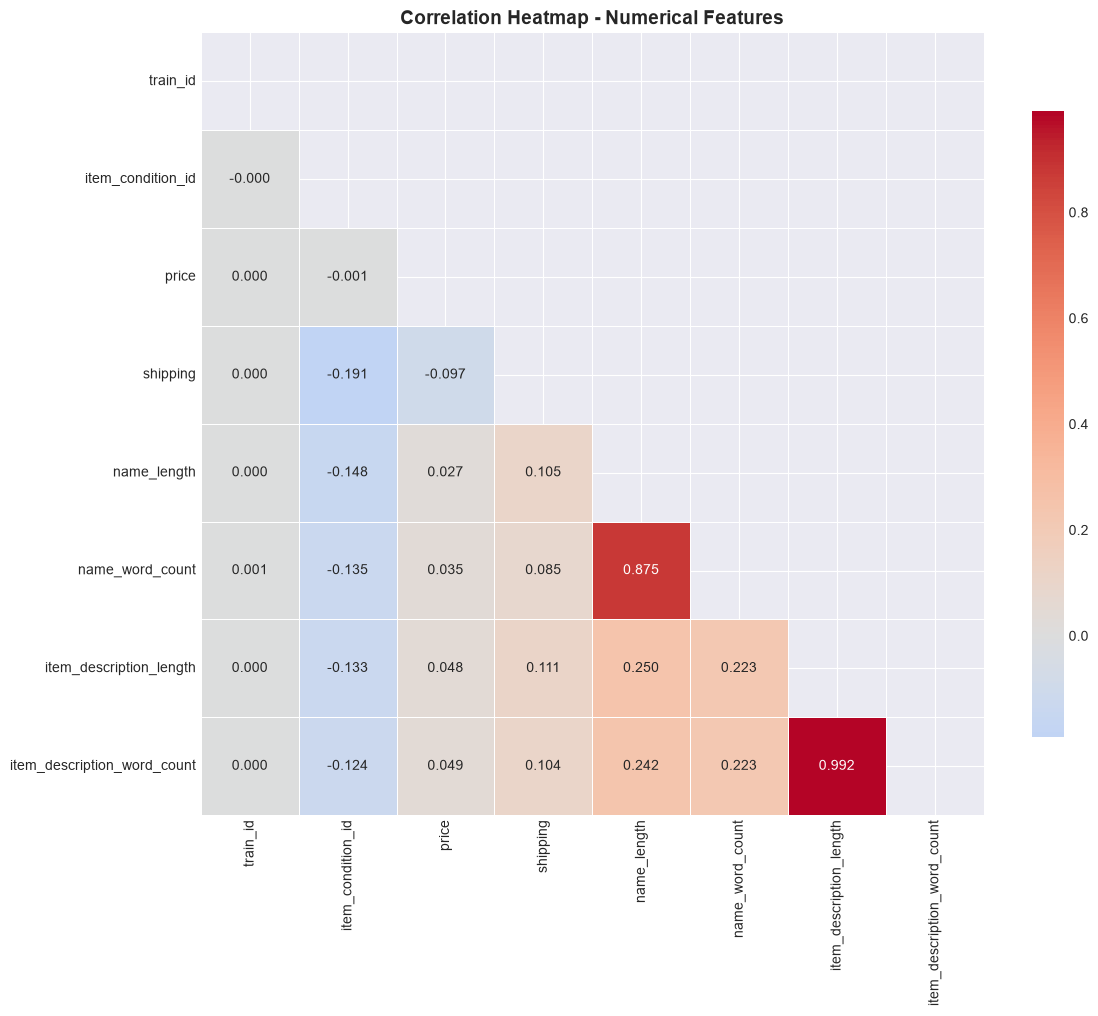


📊 Correlation with Target (Price):
price                          1.000000
item_description_word_count    0.048551
item_description_length        0.048049
name_word_count                0.034526
name_length                    0.027069
train_id                       0.000478
item_condition_id             -0.000807
shipping                      -0.097211
Name: price, dtype: float64


In [20]:
print("\n" + "=" * 60)
print("CORRELATION ANALYSIS")
print("=" * 60)

# Select numerical columns for correlation
numerical_for_corr = df.select_dtypes(include=[np.number]).columns.tolist()

# Calculate correlation matrix
correlation_matrix = df[numerical_for_corr].corr()

print("\n📊 Correlation Matrix:")
print(correlation_matrix)

# Visualize correlation heatmap
plt.figure(figsize=(12, 10))
mask = np.triu(np.ones_like(correlation_matrix, dtype=bool))
sns.heatmap(correlation_matrix, mask=mask, annot=True, fmt='.3f', cmap='coolwarm',
            center=0, square=True, linewidths=0.5, cbar_kws={"shrink": 0.8})
plt.title('Correlation Heatmap - Numerical Features', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Correlation with target
print("\n📊 Correlation with Target (Price):")
target_correlations = correlation_matrix[target_col].sort_values(ascending=False)
print(target_correlations)

## Step 15: Advanced Analysis - Price Ranges


ADVANCED ANALYSIS - PRICE RANGES

📊 Price Range Distribution:
price_range
$0-10        277073
$10-20       556586
$20-50       489523
$50-100      115040
$100-200      33466
$200-500       9679
$500-1000       991
$1000+          177
Name: count, dtype: int64

Price Range Percentages:
price_range
$0-10        18.69
$10-20       37.54
$20-50       33.02
$50-100       7.76
$100-200      2.26
$200-500      0.65
$500-1000     0.07
$1000+        0.01
Name: count, dtype: float64


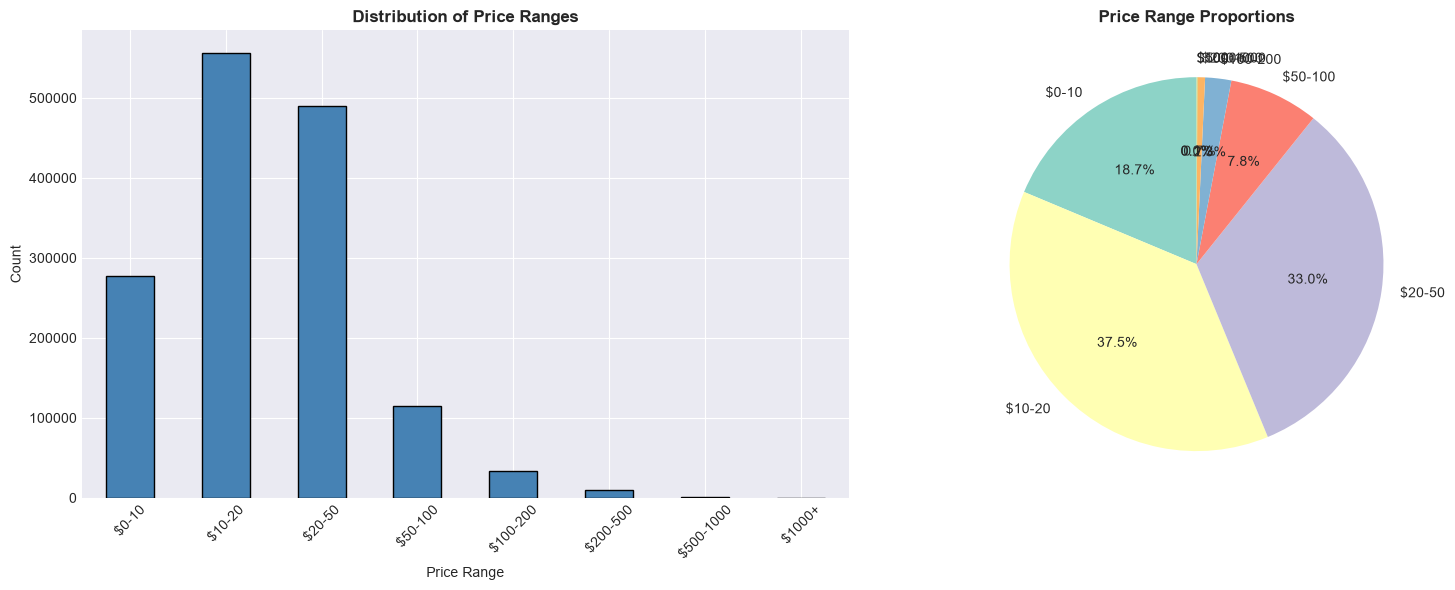

In [21]:
print("\n" + "=" * 60)
print("ADVANCED ANALYSIS - PRICE RANGES")
print("=" * 60)

# Create price bins
price_bins = [0, 10, 20, 50, 100, 200, 500, 1000, float('inf')]
price_labels = ['$0-10', '$10-20', '$20-50', '$50-100', '$100-200', '$200-500', '$500-1000', '$1000+']

df['price_range'] = pd.cut(df[target_col], bins=price_bins, labels=price_labels, right=False)

print("\n📊 Price Range Distribution:")
price_range_dist = df['price_range'].value_counts().sort_index()
print(price_range_dist)
print(f"\nPrice Range Percentages:")
print((price_range_dist / len(df) * 100).round(2))

# Visualize price ranges
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Count plot
price_range_dist.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='black')
axes[0].set_title('Distribution of Price Ranges', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Price Range')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=45)

# Pie chart
axes[1].pie(price_range_dist.values, labels=price_range_dist.index, autopct='%1.1f%%',
            startangle=90, colors=plt.cm.Set3.colors)
axes[1].set_title('Price Range Proportions', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Step 16: Data Quality Issues Summary

In [22]:
print("\n" + "=" * 60)
print("DATA QUALITY ISSUES SUMMARY")
print("=" * 60)

issues_summary = {
    'Issue': [],
    'Count': [],
    'Percentage': [],
    'Severity': []
}

# Missing values
for col in df.columns:
    missing_count = df[col].isnull().sum()
    if missing_count > 0:
        issues_summary['Issue'].append(f'Missing values in {col}')
        issues_summary['Count'].append(missing_count)
        issues_summary['Percentage'].append(f"{(missing_count/len(df))*100:.2f}%")
        severity = 'High' if (missing_count/len(df))*100 > 20 else 'Medium' if (missing_count/len(df))*100 > 5 else 'Low'
        issues_summary['Severity'].append(severity)

# Duplicates
duplicates = df.duplicated().sum()
if duplicates > 0:
    issues_summary['Issue'].append('Duplicate rows')
    issues_summary['Count'].append(duplicates)
    issues_summary['Percentage'].append(f"{(duplicates/len(df))*100:.2f}%")
    issues_summary['Severity'].append('Medium')

# Outliers
outliers = len(outliers_iqr)
issues_summary['Issue'].append('Price outliers (IQR method)')
issues_summary['Count'].append(outliers)
issues_summary['Percentage'].append(f"{(outliers/len(df))*100:.2f}%")
issues_summary['Severity'].append('Medium')

# Zero or negative prices
zero_prices = (df[target_col] <= 0).sum()
if zero_prices > 0:
    issues_summary['Issue'].append('Zero or negative prices')
    issues_summary['Count'].append(zero_prices)
    issues_summary['Percentage'].append(f"{(zero_prices/len(df))*100:.2f}%")
    issues_summary['Severity'].append('High')

issues_df = pd.DataFrame(issues_summary)
print("\n📊 Data Quality Issues Summary:")
print(issues_df.to_string(index=False))


DATA QUALITY ISSUES SUMMARY

📊 Data Quality Issues Summary:
                             Issue  Count Percentage Severity
   Missing values in category_name   6327      0.43%      Low
      Missing values in brand_name 632682     42.68%     High
Missing values in item_description      6      0.00%      Low
       Price outliers (IQR method) 119352      8.05%   Medium
           Zero or negative prices    874      0.06%     High


## Step 17: Key Insights & Patterns

In [23]:
print("\n" + "=" * 60)
print("KEY INSIGHTS & PATTERNS")
print("=" * 60)

insights = f"""
📊 DATASET OVERVIEW:
• Total records: {len(df):,}
• Total features: {len(df.columns)}
• Target variable: {target_col} (highly right-skewed)
• Price range: ${df[target_col].min():.2f} - ${df[target_col].max():.2f}

🔍 DATA QUALITY FINDINGS:
• Missing values in brand_name: {df['brand_name'].isnull().sum() if 'brand_name' in df.columns else 'N/A'} ({(df['brand_name'].isnull().sum()/len(df))*100:.2f}%)
• Missing values in category_name: {df['category_name'].isnull().sum() if 'category_name' in df.columns else 'N/A'} ({(df['category_name'].isnull().sum()/len(df))*100:.2f}%)
• Missing values in item_description: {df['item_description'].isnull().sum() if 'item_description' in df.columns else 'N/A'} ({(df['item_description'].isnull().sum()/len(df))*100:.2f}%)
• Outliers detected: {len(outliers_iqr):,} ({(len(outliers_iqr)/len(df))*100:.2f}%)

📈 DISTRIBUTION INSIGHTS:
• Price is highly right-skewed (skewness: {skew(df[target_col]):.2f})
• Log transformation recommended for price
• Item condition shows {'significant' if 'item_condition_id' in df.columns else 'no'} variation in pricing
• Shipping has {'a' if 'shipping' in df.columns else 'no'} notable impact on price

🔗 CORRELATION INSIGHTS:
• Strongest predictor: {target_correlations.index[1] if len(target_correlations) > 1 else 'N/A'} (correlation: {target_correlations.iloc[1]:.3f})
• Text features show {'moderate' if 'name_length' in df.columns else 'no'} correlation with price

🎯 RECOMMENDATIONS:
1. Apply log transformation to price
2. Handle missing values in brand_name and category_name
3. Remove or cap extreme outliers
4. Engineer features from text (length, word count)
5. Encode categorical features appropriately
"""

print(insights)


KEY INSIGHTS & PATTERNS

📊 DATASET OVERVIEW:
• Total records: 1,482,535
• Total features: 16
• Target variable: price (highly right-skewed)
• Price range: $0.00 - $2009.00

🔍 DATA QUALITY FINDINGS:
• Missing values in brand_name: 632682 (42.68%)
• Missing values in category_name: 6327 (0.43%)
• Missing values in item_description: 6 (0.00%)
• Outliers detected: 119,352 (8.05%)

📈 DISTRIBUTION INSIGHTS:
• Price is highly right-skewed (skewness: 11.39)
• Log transformation recommended for price
• Item condition shows significant variation in pricing
• Shipping has a notable impact on price

🔗 CORRELATION INSIGHTS:
• Strongest predictor: item_description_word_count (correlation: 0.049)
• Text features show moderate correlation with price

🎯 RECOMMENDATIONS:
1. Apply log transformation to price
2. Handle missing values in brand_name and category_name
3. Remove or cap extreme outliers
4. Engineer features from text (length, word count)
5. Encode categorical features appropriately



## Step 18: Save Processed Data Info

In [24]:
print("\n" + "=" * 60)
print("SAVING EDA RESULTS")
print("=" * 60)

# Save summary statistics
summary_stats = {
    'total_records': len(df),
    'total_features': len(df.columns),
    'missing_values': df.isnull().sum().to_dict(),
    'duplicates': int(df.duplicated().sum()),
    'price_stats': df[target_col].describe().to_dict(),
    'outliers_iqr': int(len(outliers_iqr)),
    'outliers_zscore': int(len(outliers_z))
}

print("\n✅ EDA Complete! Summary statistics saved.")
print("\n📊 Next Steps:")
print("1. Review data quality issues")
print("2. Proceed to preprocessing pipeline")
print("3. Feature engineering")
print("4. Model development")


SAVING EDA RESULTS

✅ EDA Complete! Summary statistics saved.

📊 Next Steps:
1. Review data quality issues
2. Proceed to preprocessing pipeline
3. Feature engineering
4. Model development
